In [1]:
import sys, time, hashlib, requests
import pandas as pd
from datetime import datetime
from pathlib import Path
from urllib.parse import urljoin
from bs4 import BeautifulSoup

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "books_raw.csv"

sys.path.append(str(ROOT / "src"))
from config import SEED
print("SEED =", SEED)

SEED = 3020


### What above cell does:
This cell imports the libraries and sets the file paths. It also loads the SEED from the config file. The SEED is 3020, which is the last four digits of the lowest roll number in our team. The output shows SEED = 3020, so the config file loaded correctly.

In [2]:
START_URL = "https://books.toscrape.com/catalogue/page-1.html"
SLEEP = 0.5
MAX_RETRIES = 3

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (university project scraper)"})
request_count = 0
failed_urls = []

def get_soup(url):
    global request_count
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            request_count += 1
            r = session.get(url, timeout=15)
            r.raise_for_status()
            r.encoding = "utf-8"
            time.sleep(SLEEP)
            return BeautifulSoup(r.text, "html.parser")
        except requests.RequestException as e:
            print(f"[retry {attempt}/{MAX_RETRIES}] {url} -> {e}")
            time.sleep(2 * attempt)
    failed_urls.append(url)
    return None

def get_product_urls():
    urls, pages, page_url = [], 0, START_URL
    while page_url:
        soup = get_soup(page_url)
        if soup is None:
            break
        pages += 1
        urls += [urljoin(page_url, a["href"]) for a in soup.select("article.product_pod h3 a")]
        nxt = soup.select_one("li.next a")
        page_url = urljoin(page_url, nxt["href"]) if nxt else None
    return urls, pages

def parse_product(url):
    soup = get_soup(url)
    if soup is None:
        return None
    table = {tr.th.get_text(strip=True): tr.td.get_text(strip=True)
             for tr in soup.select("table.table-striped tr")}
    crumbs = soup.select("ul.breadcrumb li")
    desc_header = soup.select_one("#product_description")
    desc = desc_header.find_next_sibling("p") if desc_header else None
    rating = soup.select_one("p.star-rating")
    return {
        "title": soup.h1.get_text(strip=True),
        "product_url": url,
        "category": crumbs[2].get_text(strip=True) if len(crumbs) > 2 else None,
        "price_excl_tax": table.get("Price (excl. tax)"),
        "price_incl_tax": table.get("Price (incl. tax)"),
        "tax": table.get("Tax"),
        "rating": rating["class"][1] if rating else None,
        "availability": table.get("Availability"),
        "num_reviews": table.get("Number of reviews"),
        "upc": table.get("UPC"),
        "description": desc.get_text(strip=True) if desc else None,
        "collected_at": datetime.now().isoformat(timespec="seconds"),
    }

### What this cell does:
This cell defines the functions used for scraping and does not download anything yet. One function downloads a page with a short delay, retries on errors and counts requests. Another collects all book links from the listing pages. The third reads one book page and extracts its details with a collected_at timestamp. There is no output because these are only function definitions.

In [19]:
soup = get_soup(START_URL)
print("Books on page 1:", len(soup.select("article.product_pod")))
print("Next-page link:", soup.select_one("li.next a")["href"])

cats = soup.select("div.side_categories ul li ul li a")
print("Categories in sidebar:", len(cats))

first = urljoin(START_URL, soup.select_one("article.product_pod h3 a")["href"])
print("Example product page:", first)
print(parse_product(first))

Books on page 1: 20
Next-page link: page-2.html
Categories in sidebar: 50
Example product page: https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
{'title': 'A Light in the Attic', 'product_url': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html', 'category': 'Poetry', 'price_excl_tax': '£51.77', 'price_incl_tax': '£51.77', 'tax': '£0.00', 'rating': 'Three', 'availability': 'In stock (22 available)', 'num_reviews': '0', 'upc': 'a897fe39b1053632', 'description': "It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings

### What this cell does:
This cell tests the scraper on the first page and on one product page. It helps me understand how the site works before the full run. Listing pages have a next link for pagination, the sidebar has the category pages, and each book has its own product page. The output shows the books on page 1, the next page link, the number of categories and one example product.

In [20]:
collection_start = datetime.now()

product_urls, n_pages = get_product_urls()
product_urls = list(dict.fromkeys(product_urls))
print("Listing pages visited:", n_pages, "| unique product URLs:", len(product_urls))

rows = []
for i, url in enumerate(product_urls, 1):
    row = parse_product(url)
    if row:
        rows.append(row)
    if i % 100 == 0:
        print(f"{i}/{len(product_urls)} done | requests so far: {request_count}")

collection_end = datetime.now()

df = pd.DataFrame(rows)
RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RAW_PATH, index=False, encoding="utf-8", lineterminator="\n")
print("Saved", len(df), "rows to", RAW_PATH)
print("Failed URLs:", failed_urls)

Listing pages visited: 50 | unique product URLs: 1000
100/1000 done | requests so far: 152
200/1000 done | requests so far: 252
300/1000 done | requests so far: 352
400/1000 done | requests so far: 452
500/1000 done | requests so far: 552
600/1000 done | requests so far: 652
700/1000 done | requests so far: 752
800/1000 done | requests so far: 852
900/1000 done | requests so far: 952
1000/1000 done | requests so far: 1052
Saved 1000 rows to C:\Users\DELL\data\E-commerce\data\raw\books_raw.csv
Failed URLs: []


### What this cell does:
This cell runs the full scrape. It visits all 50 listing pages and then every product page. The data is saved as books_raw.csv with one book per row. The values are saved exactly as scraped, and no rows were copied or invented. The output shows 50 pages visited, 1000 unique links found and 1000 rows saved.

In [21]:
ROLL_NUMBERS = ["25L-3042", "25L-3020"]

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

print("Team roll numbers     :", ROLL_NUMBERS)
print("Source URL            :", "https://books.toscrape.com/")
print("Collection start      :", collection_start.isoformat(timespec="seconds"))
print("Collection end        :", collection_end.isoformat(timespec="seconds"))
print("Requests made         :", request_count)
print("Listing pages visited :", n_pages)
print("Rows collected        :", len(df))
print("collected_at filled   :", df["collected_at"].notna().all())
print("SHA-256 of raw file   :", sha256_of(RAW_PATH))

Team roll numbers     : ['25L-3042', '25L-3020']
Source URL            : https://books.toscrape.com/
Collection start      : 2026-11-19T07:35:25
Collection end        : 2026-11-19T07:50:41
Requests made         : 1052
Listing pages visited : 50
Rows collected        : 1000
collected_at filled   : True
SHA-256 of raw file   : f6129f4d7f32af7fc7dff8eef0fdf57c6aca2051987da258d5dab4fa2b0db802


### What this cell does:
This cell prints the data collection log and the SHA-256 fingerprint of the raw file. It proves the data was collected by our team, and the submitted file must match this fingerprint. Our roll numbers are 25L-3042 and 25L-3020. Collection ran from 07:35:25 to 07:50:41 on 2026-11-19. We made 1052 requests, which includes 2 extra requests from the test in Cell 3. We collected 1000 rows and every row has a collected_at value.

In [22]:
raw = pd.read_csv(RAW_PATH)
print("Rows:", len(raw))
print("Unique product URLs:", raw["product_url"].nunique(), "| Unique UPCs:", raw["upc"].nunique())
print("\nMissing values per column:\n", raw.isna().sum())
print("\nRatings:", raw["rating"].value_counts().to_dict())
print("\nAvailability formats:",
      raw["availability"].str.replace(r"\d+", "N", regex=True).value_counts().to_dict())

Rows: 1000
Unique product URLs: 1000 | Unique UPCs: 1000

Missing values per column:
 title             0
product_url       0
category          0
price_excl_tax    0
price_incl_tax    0
tax               0
rating            0
availability      0
num_reviews       0
upc               0
description       2
collected_at      0
dtype: int64

Ratings: {'One': 226, 'Three': 203, 'Five': 196, 'Two': 196, 'Four': 179}

Availability formats: {'In stock (N available)': 1000}


### What this cell does:
This cell reads the raw file and checks it for duplicates, missing values and inconsistent formats. There are 1000 rows with 1000 unique URLs and 1000 unique UPCs, so there are no duplicates. Only the description column has missing values, in 2 books, and I left them empty. Ratings are text values from One to Five. Availability always has the same format. Prices, tax and reviews are still raw text and will be cleaned in the next step.

In [23]:
cat_counts = {}
for c in cats:
    name, url = c.get_text(strip=True), urljoin(START_URL, c["href"])
    n = 0
    while url:
        s = get_soup(url)
        if s is None:
            break
        n += len(s.select("article.product_pod"))
        nxt = s.select_one("li.next a")
        url = urljoin(url, nxt["href"]) if nxt else None
    cat_counts[name] = n

check = pd.DataFrame({"category_pages": cat_counts,
                      "scraped": raw["category"].value_counts().to_dict()}).fillna(0).astype(int)
print("All categories match:", (check["category_pages"] == check["scraped"]).all())

All categories match: True


### What this cell does:
This cell visits every category page and counts the books listed. It compares these counts with the categories in my scraped data. The output shows True, so all categories match and no book was missed or counted twice. These extra requests were only for checking and are not part of the 1052 requests in the collection log.

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)

books = pd.read_csv(RAW_PATH)
display(books.head())
display(books.tail())

,title,product_url,category,price_excl_tax,price_incl_tax,tax,rating,availability,num_reviews,upc,description,collected_at
0,A Light in the Attic,https://books.toscrape.com/catalogue...,Poetry,£51.77,£51.77,£0.00,Three,In stock (22 available),0,a897fe39b1053632,It's hard to imagine a world without...,2026-11-19T07:36:10
1,Tipping the Velvet,https://books.toscrape.com/catalogue...,Historical Fiction,£53.74,£53.74,£0.00,One,In stock (20 available),0,90fa61229261140a,"""Erotic and absorbing...Written with...",2026-11-19T07:36:11
2,Soumission,https://books.toscrape.com/catalogue...,Fiction,£50.10,£50.10,£0.00,One,In stock (20 available),0,6957f44c3847a760,Dans une France assez proche de la n...,2026-11-19T07:36:12
3,Sharp Objects,https://books.toscrape.com/catalogue...,Mystery,£47.82,£47.82,£0.00,Four,In stock (20 available),0,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL acros...",2026-11-19T07:36:13
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue...,History,£54.23,£54.23,£0.00,Five,In stock (20 available),0,4165285e1663650f,From a renowned historian comes a gr...,2026-11-19T07:36:14


,title,product_url,category,price_excl_tax,price_incl_tax,tax,rating,availability,num_reviews,upc,description,collected_at
995,Alice in Wonderland (Alice's Adventu...,https://books.toscrape.com/catalogue...,Classics,£55.53,£55.53,£0.00,One,In stock (1 available),0,cd2a2a70dd5d176d,NaN,2026-11-19T07:50:37
996,"Ajin: Demi-Human, Volume 1 (Ajin: De...",https://books.toscrape.com/catalogue...,Sequential Art,£57.06,£57.06,£0.00,Four,In stock (1 available),0,bfd5e1701c862ac3,High school student Kei Nagai is str...,2026-11-19T07:50:38
997,A Spy's Devotion (The Regency Spies ...,https://books.toscrape.com/catalogue...,Historical Fiction,£16.97,£16.97,£0.00,Five,In stock (1 available),0,19fec36a1dfb4c16,"In England’s Regency era, manners an...",2026-11-19T07:50:39
998,1st to Die (Women's Murder Club #1),https://books.toscrape.com/catalogue...,Mystery,£53.98,£53.98,£0.00,One,In stock (1 available),0,f684a82adc49f011,"James Patterson, bestselling author ...",2026-11-19T07:50:40
999,"1,000 Places to See Before You Die",https://books.toscrape.com/catalogue...,Travel,£26.08,£26.08,£0.00,Five,In stock (1 available),0,228ba5e7577e1d49,"Around the World, continent by conti...",2026-11-19T07:50:41


### What this cell does:
This cell loads the raw file and shows the first and last five records. Each row is one book, and the values are still raw text.

In [14]:
print("Rows:", books.shape[0])
print("Columns:", books.shape[1])
print("Column names:", list(books.columns))

Rows: 1000
Columns: 12
Column names: ['title', 'product_url', 'category', 'price_excl_tax', 'price_incl_tax', 'tax', 'rating', 'availability', 'num_reviews', 'upc', 'description', 'collected_at']


### What this cell shows:
The dataset has 1000 rows and 12 columns. Each row is one book.

In [15]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   title           1000 non-null   str  
 1   product_url     1000 non-null   str  
 2   category        1000 non-null   str  
 3   price_excl_tax  1000 non-null   str  
 4   price_incl_tax  1000 non-null   str  
 5   tax             1000 non-null   str  
 6   rating          1000 non-null   str  
 7   availability    1000 non-null   str  
 8   num_reviews     1000 non-null   int64
 9   upc             1000 non-null   str  
 10  description     998 non-null    str  
 11  collected_at    1000 non-null   str  
dtypes: int64(1), str(11)
memory usage: 93.9 KB


### what this cell shows:
All columns have 1000 non-null values except description, which has 998. Only num_reviews is stored as a number, and the other 11 columns are stored as text.

In [16]:
numeric_cols = books.select_dtypes(include="number").columns.tolist()
boolean_cols = books.select_dtypes(include="bool").columns.tolist()
other_cols = books.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print("Stored as numbers:", numeric_cols)
print("Stored as boolean:", boolean_cols)
print("Stored as text:", other_cols)

Stored as numbers: ['num_reviews']
Stored as boolean: []
Stored as text: ['title', 'product_url', 'category', 'price_excl_tax', 'price_incl_tax', 'tax', 'rating', 'availability', 'upc', 'description', 'collected_at']


### What this cell shows:
Only num_reviews is stored as a number, and there are no boolean columns. By meaning, the price and tax columns are numerical but stored as text. Category, rating and availability are categorical, title and description are text, and product_url and upc are identifiers.

In [17]:
display(books.describe())
display(books.describe(include="all").T)

,num_reviews
count,1000.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,1000,999,The Star-Touched Queen,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_url,1000,1000,https://books.toscrape.com/catalogue...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1000,50,Default,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_excl_tax,1000,903,£44.18,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_incl_tax,1000,903,£44.18,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax,1000,1,£0.00,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1000,5,One,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,1000,21,In stock (3 available),196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_reviews,1000.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
upc,1000,1000,a897fe39b1053632,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### What this cell shows:
Only num_reviews is numeric, and it has just one unique value, so its statistics are the same for every book. The second table summarizes all columns, including the most frequent value of each text column.

In [18]:
print(books.nunique(), "\n")
for col in ["category", "rating", "availability"]:
    print(col, "- unique values:", books[col].nunique())
    print(books[col].value_counts().head(15), "\n")
print(books["rating"].value_counts().reindex(["One", "Two", "Three", "Four", "Five"]))

title              999
product_url       1000
category            50
price_excl_tax     903
price_incl_tax     903
tax                  1
rating               5
availability        21
num_reviews          1
upc               1000
description        998
collected_at       855
dtype: int64 

category - unique values: 50
category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics               19
History                18
Name: count, dtype: int64 

rating - unique values: 5
rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64 

availability - unique values: 21
availability
In stock (3 available)     196
In stock (14 available)    136
In stock (1 availab

### What this cell shows:
There are 50 categories, and the largest is Default with 152 books. Default and Add a comment are labels used by the website and are not real genres. Rating has five values from One to Five. Availability has 21 values only because the stock number changes. Tax and num_reviews each have a single unique value.

In [22]:
print(books["tax"].unique(), books["num_reviews"].unique())

<StringArray>
['£0.00']
Length: 1, dtype: str [0]


### What this cell shows:
This cell shows the unique values of tax and num_reviews. Tax is always ['£0.00'], and num_reviews is always 0.

In [19]:
print(books.memory_usage(deep=True))
total = books.memory_usage(deep=True).sum()
print("Total memory:", round(total / 1024, 1), "KB")

Index                 132
title               89526
product_url        138115
category            58516
price_excl_tax      79000
price_incl_tax      79000
tax                 77000
rating              52781
availability        71420
num_reviews          8000
upc                 65000
description       2342675
collected_at        68000
dtype: int64
Total memory: 3055.8 KB


### What this cell does:
The dataset uses about 3056 KB of memory, and most of it comes from the description column because it holds long text.

In [20]:
missing = books.isna().sum()
percent = (missing / len(books) * 100).round(2)
print(pd.DataFrame({"missing": missing, "percent": percent}))

                missing  percent
title                 0      0.0
product_url           0      0.0
category              0      0.0
price_excl_tax        0      0.0
price_incl_tax        0      0.0
tax                   0      0.0
rating                0      0.0
availability          0      0.0
num_reviews           0      0.0
upc                   0      0.0
description           2      0.2
collected_at          0      0.0


### What this cell shows:
Only description has missing values, 2 out of 1000 books, which is 0.2 percent.

In [21]:
print("Fully duplicated rows:", books.duplicated().sum())
print("Duplicate product URLs:", books.duplicated(subset="product_url").sum())
print("Duplicate UPCs:", books.duplicated(subset="upc").sum())
print("Repeated titles:", books["title"].duplicated().sum())

Fully duplicated rows: 0
Duplicate product URLs: 0
Duplicate UPCs: 0
Repeated titles: 1


### What this cell shows:
There are no duplicate rows, URLs or UPCs. One title appears twice, but the two books have different URLs and UPCs.

In [23]:
books[books["title"].duplicated(keep=False)]

,title,product_url,category,price_excl_tax,price_incl_tax,tax,rating,availability,num_reviews,upc,description,collected_at
236,The Star-Touched Queen,https://books.toscrape.com/catalogue...,Fantasy,£46.02,£46.02,£0.00,Five,In stock (14 available),0,1528279aec1f3dce,Fate and fortune. Power and passion....,2026-11-19T07:39:31
358,The Star-Touched Queen,https://books.toscrape.com/catalogue...,Fantasy,£32.30,£32.30,£0.00,Five,In stock (12 available),0,4a7a25be293ad678,Fate and fortune. Power and passion....,2026-11-19T07:41:13


### What this cell shows:
This cell shows the two books that share a title. Their URLs and UPCs are different, so they are different books.

In [3]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

TARGET_REG = "price"
TARGET_CLF = "rating_class"

orig_missing = books.isna().sum()
report = pd.DataFrame({"missing": orig_missing,
                       "percent": (orig_missing / len(books) * 100).round(2)})
print(report)

                missing  percent
title                 0      0.0
product_url           0      0.0
category              0      0.0
price_excl_tax        0      0.0
price_incl_tax        0      0.0
tax                   0      0.0
rating                0      0.0
availability          0      0.0
num_reviews           0      0.0
upc                   0      0.0
description           2      0.2
collected_at          0      0.0


### What this cell shows:
Only description has missing values in the raw data, 2 out of 1000 books or 0.2 percent. The targets are price for regression and rating_class for classification.

In [4]:
clean = books.copy()
clean["price"] = clean["price_excl_tax"].str.replace(r"[^\d.]", "", regex=True).astype(float)
price_incl = clean["price_incl_tax"].str.replace(r"[^\d.]", "", regex=True).astype(float)
print("Price incl. tax equals price excl. tax:", (clean["price"] == price_incl).all())
clean["stock"] = clean["availability"].str.extract(r"\((\d+) available\)", expand=False).astype(float)
clean["rating_num"] = clean["rating"].map({"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5})
clean["description"] = clean["description"].fillna("")
clean["desc_length"] = clean["description"].str.len().astype(float)
clean["title_length"] = clean["title"].str.len().astype(float)
clean["collected_at"] = pd.to_datetime(clean["collected_at"])
clean["rating_class"] = pd.cut(clean["rating_num"], bins=[0, 2, 3, 5],labels=["Low", "Medium", "High"])
display(clean[["price", "stock", "rating", "rating_num", "rating_class", "desc_length", "title_length"]].head())

Price incl. tax equals price excl. tax: True


,price,stock,rating,rating_num,rating_class,desc_length,title_length
0,51.77,22.0,Three,3,Medium,1017.0,20.0
1,53.74,20.0,One,1,Low,1029.0,18.0
2,50.10,20.0,One,1,Low,1093.0,10.0
3,47.82,20.0,Four,4,High,1635.0,13.0
4,54.23,20.0,Five,5,High,1945.0,37.0


### What this cell does:
This cell makes a working copy and converts the text into usable columns such as price, stock and rating number. It also adds description and title length. Price including tax equals price excluding tax because the tax is always zero. Ratings are grouped into Low (1 and 2 stars), Medium (3 stars) and High (4 and 5 stars).

In [5]:
print(clean["rating_class"].value_counts().reindex(["Low", "Medium", "High"]))
print((clean["rating_class"].value_counts(normalize=True) * 100).round(1))

constant_cols = [c for c in clean.columns if clean[c].nunique() == 1]
print("Constant columns, not used as inputs:", constant_cols)

rating_class
Low       422
Medium    203
High      375
Name: count, dtype: int64
rating_class
Low       42.2
High      37.5
Medium    20.3
Name: proportion, dtype: float64
Constant columns, not used as inputs: ['tax', 'num_reviews']


### What this cell shows:
The classes are Low 422, Medium 203 and High 375, so Medium is the smallest class. Tax and num_reviews are constant, so they are not used as inputs.

In [6]:
cols_no_time = [c for c in clean.columns if c != "collected_at"]
print("Exact duplicate rows:", clean.duplicated().sum())
print("Duplicates ignoring collected_at:", clean.duplicated(subset=cols_no_time).sum())
before = len(clean)
clean = clean.drop_duplicates(subset=cols_no_time).reset_index(drop=True)
print("Rows before:", before, "| removed:", before - len(clean), "| rows after:", len(clean))

Exact duplicate rows: 0
Duplicates ignoring collected_at: 0
Rows before: 1000 | removed: 0 | rows after: 1000


### What this cell shows:
No duplicate records were found, so 0 rows were removed and 1000 rows remain.

In [29]:
MISSING_COLS = ["stock", "desc_length", "category"]
assert TARGET_REG not in MISSING_COLS and TARGET_CLF not in MISSING_COLS

rng = np.random.default_rng(SEED)
demo = clean.copy()
injected = {}
for col in MISSING_COLS:
    idx = rng.choice(demo.index.to_numpy(), size=int(0.05 * len(demo)), replace=False)
    injected[col] = idx
    demo.loc[idx, col] = np.nan

miss = demo[MISSING_COLS].isna().sum()
print(pd.DataFrame({"missing": miss, "percent": (miss / len(demo) * 100).round(2)}))

             missing  percent
stock             50      5.0
desc_length       50      5.0
category          50      5.0


### What this cell does:
This cell adds about 5 percent missing values to stock, description length and category on a copy of the data. The targets were not changed.

In [30]:
imputed = demo.copy()
for col in ["stock", "desc_length"]:
    skew = demo[col].skew()
    use_median = abs(skew) > 1
    value = demo[col].median() if use_median else demo[col].mean()
    imputed[col] = demo[col].fillna(value)
    print(col, "| skew:", round(skew, 2), "| used:", "median" if use_median else "mean", "| value:", round(value, 2))

imputed["category"] = demo["category"].fillna(demo["category"].mode()[0])

print(pd.DataFrame({"before": demo[MISSING_COLS].isna().sum(),
                    "after": imputed[MISSING_COLS].isna().sum()}))

stock | skew: 0.24 | used: mean | value: 8.46
desc_length | skew: 2.72 | used: median | value: 1352.5
             before  after
stock            50      0
desc_length      50      0
category         50      0


### What this cell does:
Stock is not skewed, so I filled it with the mean. Description length is skewed, so I used the median. Category was filled with the most frequent value. Every column went from 50 missing values to 0.

In [31]:
for col in ["stock", "desc_length"]:
    idx = injected[col]
    err = (imputed.loc[idx, col] - clean.loc[idx, col]).abs().mean()
    print(col, "mean absolute error:", round(err, 2))

idx = injected["category"]
share = (imputed.loc[idx, "category"] == clean.loc[idx, "category"]).mean()
print("category: share of imputed values that were correct:", round(share, 3))

stock mean absolute error: 6.19
desc_length mean absolute error: 338.1
category: share of imputed values that were correct: 0.06


### What this cell shows:
The average error is 6.19 for stock and 338.1 for description length, and only 6 percent of the categories were correct. Filling with a typical value cannot recover the true value.

In [32]:
onehot = pd.get_dummies(clean["category"], prefix="cat", dtype=int)
print("One-hot shape:", onehot.shape)
display(onehot.head())

print(clean[["rating", "rating_num", "rating_class"]].drop_duplicates().sort_values("rating_num"))

One-hot shape: (1000, 50)


,cat_Academic,cat_Add a comment,cat_Adult Fiction,cat_Art,cat_Autobiography,cat_Biography,cat_Business,cat_Childrens,cat_Christian,cat_Christian Fiction,cat_Classics,cat_Contemporary,cat_Crime,cat_Cultural,cat_Default,cat_Erotica,cat_Fantasy,cat_Fiction,cat_Food and Drink,cat_Health,cat_Historical,cat_Historical Fiction,cat_History,cat_Horror,cat_Humor,cat_Music,cat_Mystery,cat_New Adult,cat_Nonfiction,cat_Novels,cat_Paranormal,cat_Parenting,cat_Philosophy,cat_Poetry,cat_Politics,cat_Psychology,cat_Religion,cat_Romance,cat_Science,cat_Science Fiction,cat_Self Help,cat_Sequential Art,cat_Short Stories,cat_Spirituality,cat_Sports and Games,cat_Suspense,cat_Thriller,cat_Travel,cat_Womens Fiction,cat_Young Adult
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


   rating  rating_num rating_class
1     One           1          Low
10    Two           2          Low
0   Three           3       Medium
3    Four           4         High
4    Five           5         High


### What this cell does:
Category has no order, so I used one-hot encoding. The star rating has an order, so I kept it as numbers from 1 to 5.

In [33]:
numeric_features = ["stock", "desc_length", "title_length"]

minmax = pd.DataFrame(MinMaxScaler().fit_transform(clean[numeric_features]), columns=numeric_features)
zscore = pd.DataFrame(StandardScaler().fit_transform(clean[numeric_features]), columns=numeric_features)

print("Min-Max (min and max):\n", minmax.agg(["min", "max"]).round(3))
print("Z-score (mean and std):\n", pd.DataFrame({"mean": zscore.mean(), "std": zscore.std(ddof=0)}).round(3))

Min-Max (min and max):
      stock  desc_length  title_length
min    0.0          0.0           0.0
max    1.0          1.0           1.0
Z-score (mean and std):
               mean  std
stock         -0.0  1.0
desc_length    0.0  1.0
title_length  -0.0  1.0


### What this cell shows:
Min-Max normalization gives every column a range of 0 to 1. Z-score standardization gives every column a mean of 0 and a standard deviation of 1. Scaling puts the columns on the same range.

In [7]:
reg_features_num = ["stock", "desc_length", "title_length", "rating_num"]
reg_features_cat = ["category"]
clf_features_num = ["price", "stock", "desc_length", "title_length"]
clf_features_cat = ["category"]
assert not {"price", "price_excl_tax", "price_incl_tax", "tax"} & set(reg_features_num + reg_features_cat)
assert not {"rating", "rating_num", "rating_class"} & set(clf_features_num + clf_features_cat)
assert not set(constant_cols) & set(reg_features_num + reg_features_cat + clf_features_num + clf_features_cat)
print("Regression inputs:", reg_features_num + reg_features_cat)
print("Classification inputs:", clf_features_num + clf_features_cat)
print("No leakage between targets and inputs")

Regression inputs: ['stock', 'desc_length', 'title_length', 'rating_num', 'category']
Classification inputs: ['price', 'stock', 'desc_length', 'title_length', 'category']
No leakage between targets and inputs


### What this cell shows:
For regression I removed the price and tax columns because they repeat the target. For classification I removed the star rating and anything made from it. The leakage checks passed.

In [8]:
PROCESSED_PATH = ROOT / "data" / "processed" / "books_clean.csv"
clean.to_csv(PROCESSED_PATH, index=False)
print("Saved", len(clean), "rows to", PROCESSED_PATH)

Saved 1000 rows to C:\Users\DELL\data\E-commerce\data\processed\books_clean.csv


### What this cell does:
The cleaned data was saved with 1000 rows, without the artificial missing values or scaling.

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150)
    plt.show()

num_cols = ["price", "stock", "desc_length", "title_length", "rating_num"]
display(clean[num_cols].describe().round(2))
print("Skewness:\n", clean[num_cols].skew().round(2))

,price,stock,desc_length,title_length,rating_num
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,35.07,8.59,1431.63,39.10,2.92
std,14.45,5.65,669.32,25.75,1.43
min,10.00,1.00,0.00,2.00,1.00
25%,22.11,3.00,1069.75,19.00,2.00
50%,35.98,7.00,1348.50,35.00,3.00
75%,47.46,14.00,1681.50,53.00,4.00
max,59.99,22.00,8646.00,204.00,5.00


Skewness:
 price          -0.04
stock           0.21
desc_length     2.71
title_length    1.38
rating_num      0.07
dtype: float64


### What this cell shows:
This cell shows summary statistics and skewness. The average price is 35.07, with prices from 10.00 to 59.99. Description length is strongly right skewed with a skew of 2.71, and title length is also right skewed with a skew of 1.38. Price, stock and rating are close to symmetric.

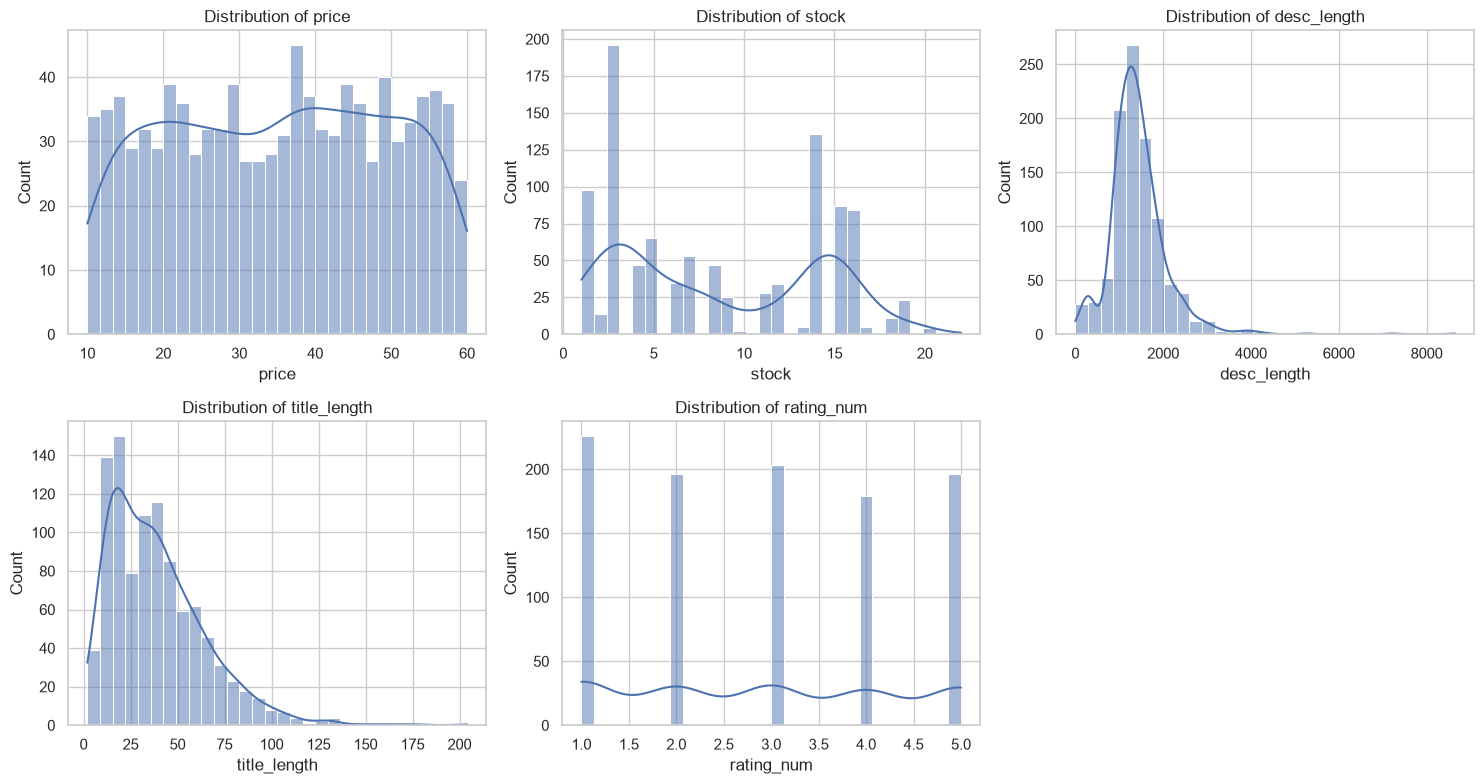

In [39]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(clean[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
axes.flat[-1].axis("off")
save_fig("histograms.png")

### What this cell shows:
The histograms show the shape of each numerical feature. Price is spread fairly evenly with no strong skew. Description length and title length have long tails to the right, which matches their high skewness

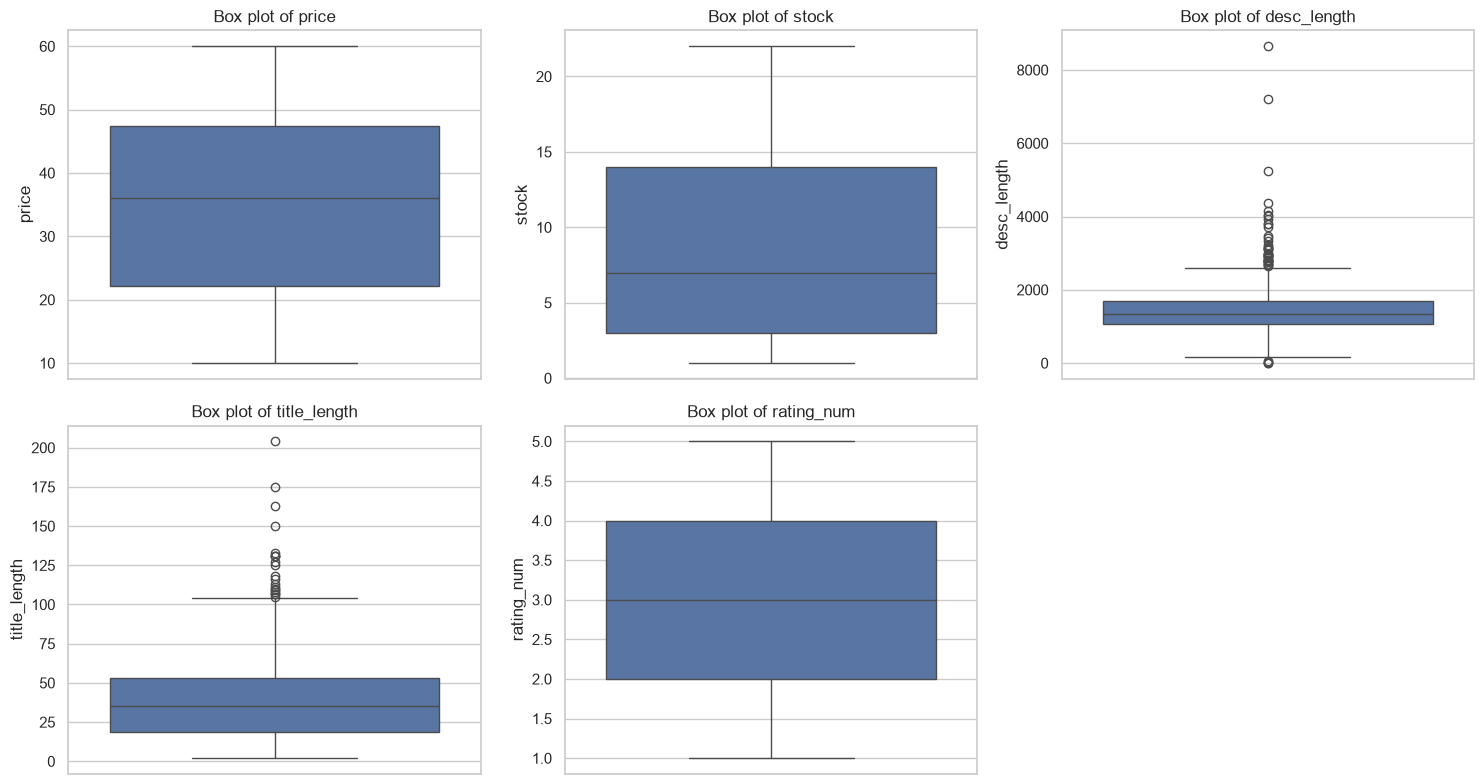

,feature,lower_limit,upper_limit,outliers,percent
0,price,-15.92,85.48,0,0.0
1,stock,-13.50,30.50,0,0.0
2,desc_length,152.12,2599.12,43,4.3
3,title_length,-32.00,104.00,20,2.0
4,rating_num,-1.00,7.00,0,0.0


In [40]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=clean[col], ax=ax)
    ax.set_title(f"Box plot of {col}")
axes.flat[-1].axis("off")
save_fig("boxplots.png")

rows = []
for col in num_cols:
    q1, q3 = clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((clean[col] < low) | (clean[col] > high)).sum()
    rows.append({"feature": col, "lower_limit": round(low, 2), "upper_limit": round(high, 2),
                 "outliers": n_out, "percent": round(n_out / len(clean) * 100, 1)})
display(pd.DataFrame(rows))

### What this cell shows:
The box plots and the IQR rule show outliers only in description length (43 books, 4.3 percent) and title length (20 books, 2.0 percent). Price, stock and rating have no outliers. The longest description has 8646 characters and the longest title has 204.

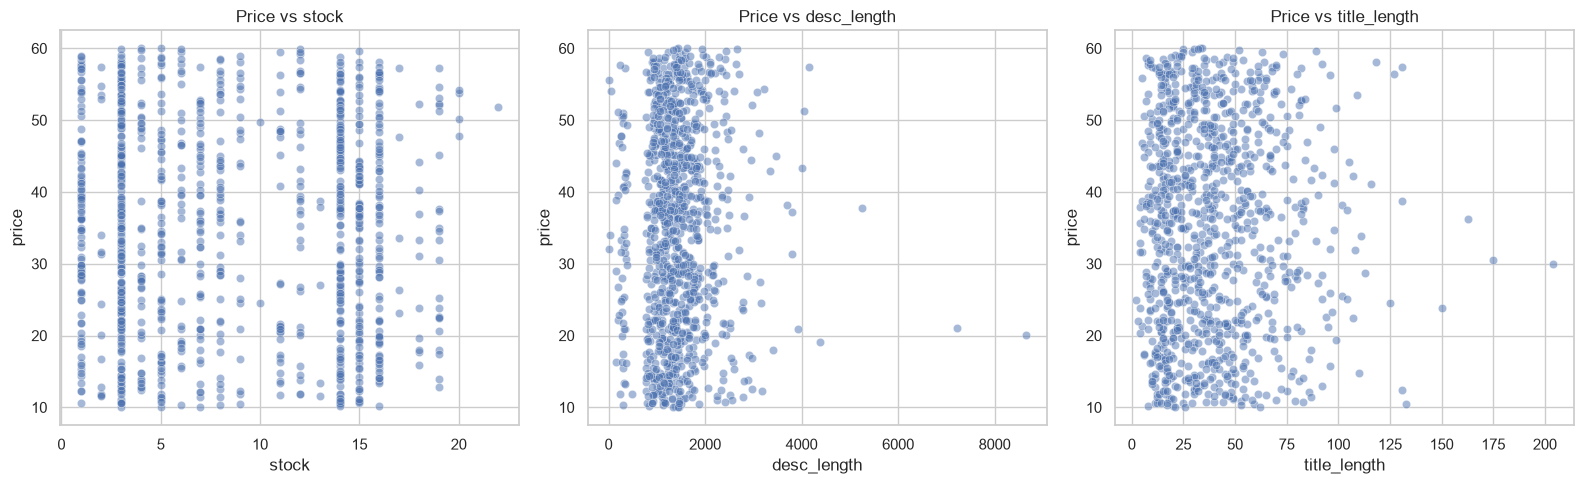

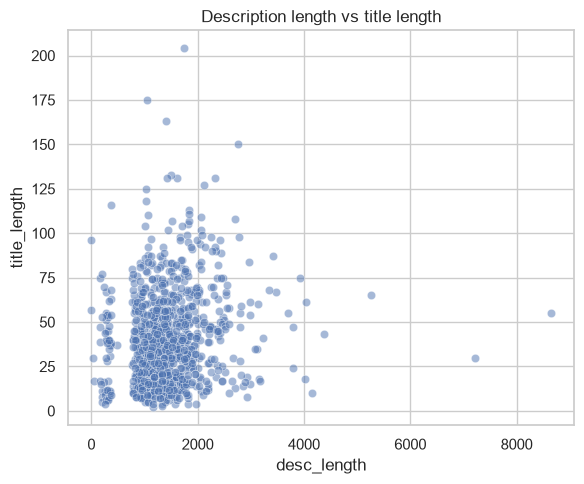

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["stock", "desc_length", "title_length"]):
    sns.scatterplot(data=clean, x=col, y="price", alpha=0.5, ax=ax)
    ax.set_title(f"Price vs {col}")
save_fig("scatter_price.png")

plt.figure(figsize=(6, 5))
sns.scatterplot(data=clean, x="desc_length", y="title_length", alpha=0.5)
plt.title("Description length vs title length")
save_fig("scatter_lengths.png")

### What this cell shows:
The scatter plots compare price with stock, description length and title length.

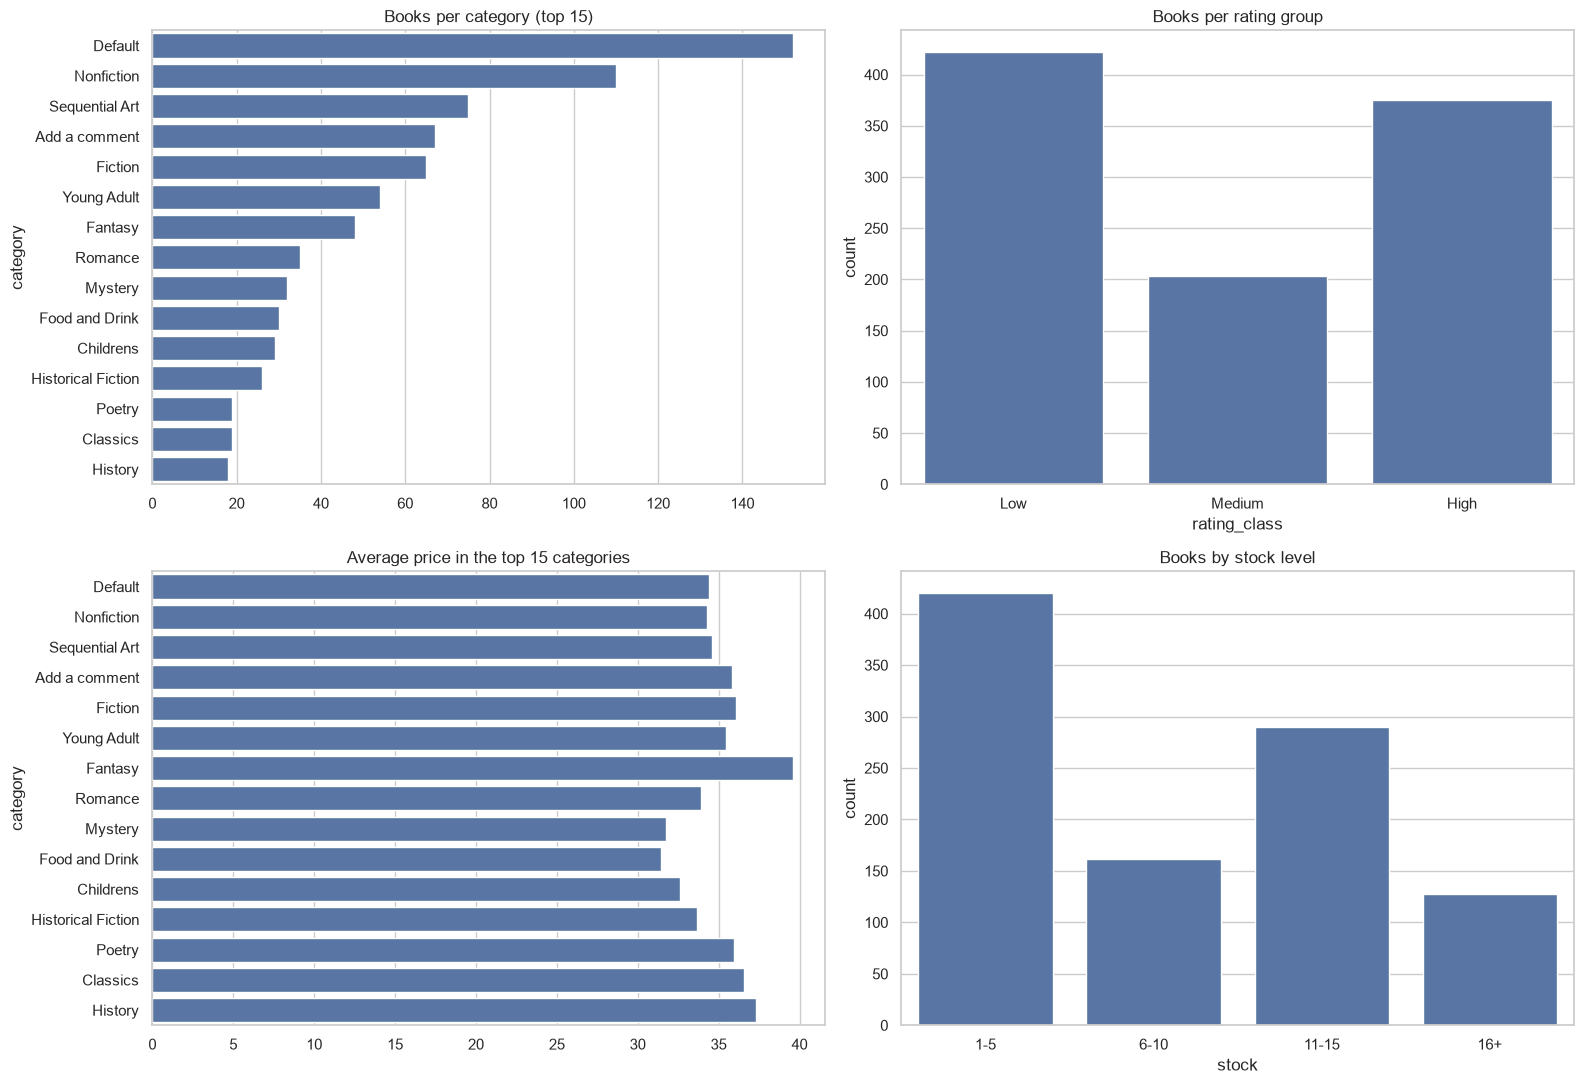

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

top_cat = clean["category"].value_counts().head(15)
sns.barplot(x=top_cat.values, y=top_cat.index, ax=axes[0, 0])
axes[0, 0].set_title("Books per category (top 15)")

order = ["Low", "Medium", "High"]
sns.countplot(data=clean, x="rating_class", order=order, ax=axes[0, 1])
axes[0, 1].set_title("Books per rating group")

avg_price_cat = clean.groupby("category")["price"].mean().loc[top_cat.index]
sns.barplot(x=avg_price_cat.values, y=avg_price_cat.index, ax=axes[1, 0])
axes[1, 0].set_title("Average price in the top 15 categories")

stock_bins = pd.cut(clean["stock"], bins=[0, 5, 10, 15, 25], labels=["1-5", "6-10", "11-15", "16+"])
sns.countplot(x=stock_bins, ax=axes[1, 1])
axes[1, 1].set_title("Books by stock level")

save_fig("bar_charts.png")

### What this cell shows:
The bar charts compare categories, rating groups and stock levels. Default has the most books with 152, followed by Nonfiction with 110 and Sequential Art with 75. Default is a label used by the website and not a real genre. Low has 422 books, Medium 203 and High 375

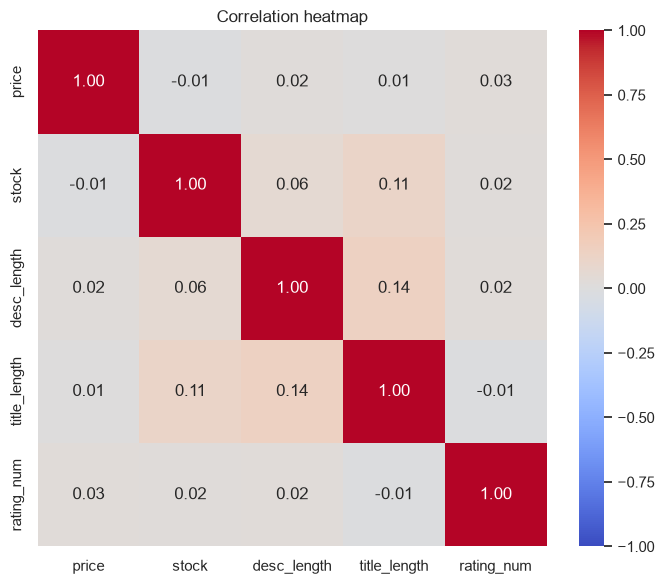

In [43]:
corr = clean[num_cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
save_fig("correlation_heatmap.png")

### What this cell does:
The heatmap shows the correlations between the numerical features. Price has very weak correlations with all other features.

In [44]:
display(clean.groupby("rating_class", observed=True)["price"].agg(["count", "mean", "median", "std"]).round(2))
display(clean.groupby("category")["price"].agg(["count", "mean"]).query("count >= 20").sort_values("mean").round(2))
print("Correlation of price with other features:\n", corr["price"].drop("price").round(3))

,count,mean,median,std
rating_class,,,,
Low,422,34.68,35.96,13.78
Medium,203,34.69,33.78,14.70
High,375,35.72,37.34,15.05


,count,mean
category,,
Food and Drink,30,31.41
Mystery,32,31.72
Childrens,29,32.64
Historical Fiction,26,33.64
Romance,35,33.93
Nonfiction,110,34.26
Default,152,34.39
Sequential Art,75,34.57
Young Adult,54,35.45


Correlation of price with other features:
 stock          -0.011
desc_length     0.021
title_length    0.007
rating_num      0.028
Name: price, dtype: float64


### What this cell shows:
The average price is almost the same across rating group: 34.68 for Low, 34.69 for Medium and 35.72 for High. Among categories with at least 20 books, Fantasy has the highest average price at 39.59 and Food and Drink the lowest at 31.41. The correlations of price with stock, description length, title length and rating are all close to zero, between minus 0.011 and 0.028. So none of these features has a clear linear relationship with price.

In [11]:
from scipy import stats

num_cols = ["price", "stock", "desc_length", "title_length", "rating_num"]
skew_before = clean[num_cols].skew()

def skew_label(s):
    if abs(s) < 0.5:
        return "approximately symmetric"
    direction = "positive (right)" if s > 0 else "negative (left)"
    return ("moderate " if abs(s) < 1 else "high ") + direction

table = pd.DataFrame({"skewness": skew_before.round(2), "type": skew_before.apply(skew_label)})
display(table)

,skewness,type
price,-0.04,approximately symmetric
stock,0.21,approximately symmetric
desc_length,2.71,high positive (right)
title_length,1.38,high positive (right)
rating_num,0.07,approximately symmetric


### What this cell shows:
Description length (2.71) and title length (1.38) are highly right skewed. Price, stock and rating are approximately symmetric, so we leave them unchanged.

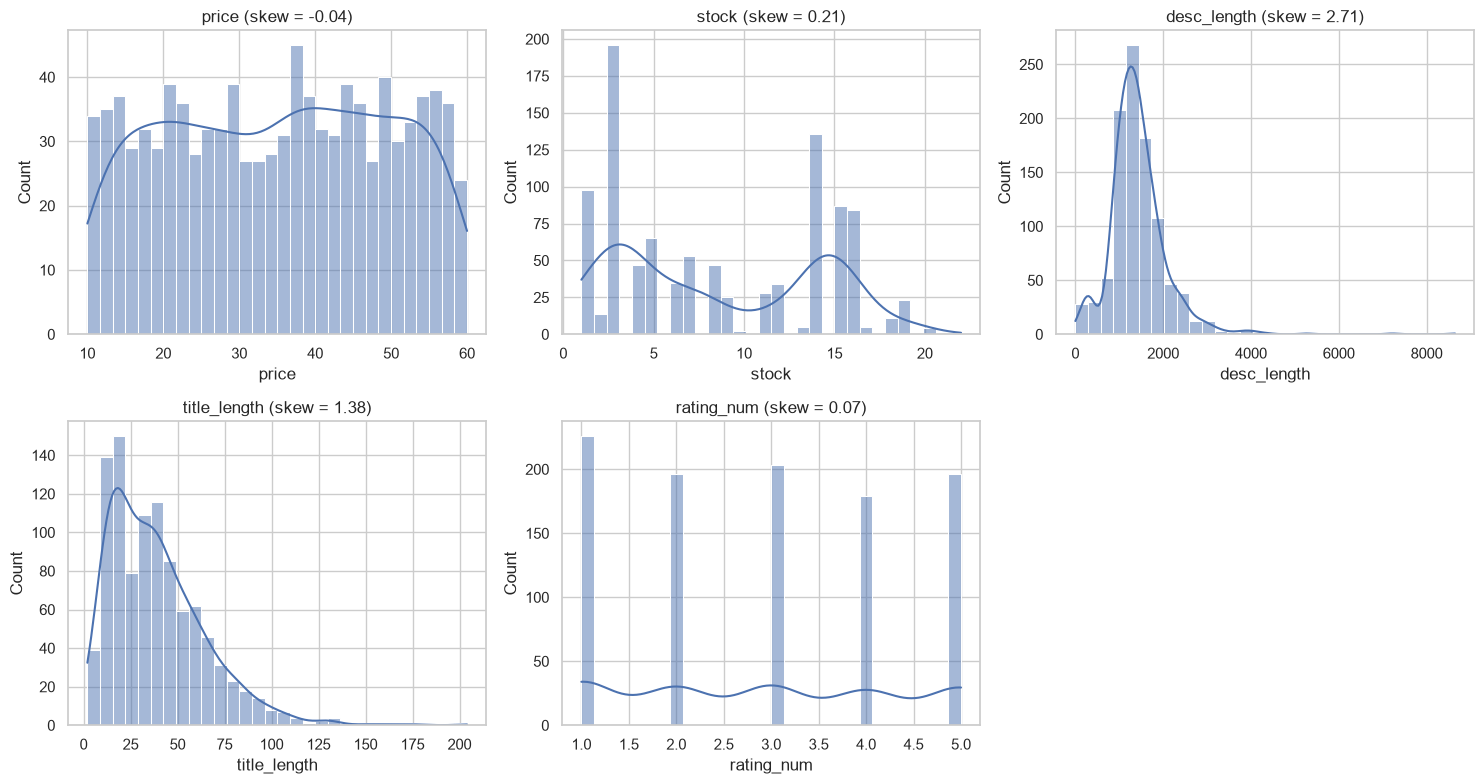

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(clean[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"{col} (skew = {skew_before[col]:.2f})")
axes.flat[-1].axis("off")
save_fig("skew_histograms_before.png")

### What this cell shows:
Price is spread fairly evenly and stock has two peaks, around 3 and 14. Description length and title length have long right tails. Rating has five bars of similar height.

In [13]:
from sklearn.preprocessing import PowerTransformer

candidates = ["desc_length", "title_length"]
rows = []
for col in candidates:
    x = clean[col]
    yj = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(clean[[col]]).ravel()
    rows.append({"feature": col,
                 "original": x.skew(),
                 "log1p": np.log1p(x).skew(),
                 "square_root": np.sqrt(x).skew(),
                 "yeo_johnson": pd.Series(yj).skew()})
display(pd.DataFrame(rows).round(2))

,feature,original,log1p,square_root,yeo_johnson
0,desc_length,2.71,-4.29,0.19,0.33
1,title_length,1.38,-0.35,0.43,-0.02


### What this cell shows:
I tried log, square root and Yeo-Johnson on the two skewed features. For description length the log made the skew worse (minus 4.29), while square root gave 0.19. For title length the log gave minus 0.35, which is good. I chose square root for description length and log for title length.

In [18]:
clean = clean.drop(columns=["desc_length_log"], errors="ignore")

clean["desc_length_sqrt"] = np.sqrt(clean["desc_length"])
clean["title_length_log"] = np.log1p(clean["title_length"])

after = pd.Series({"desc_length": clean["desc_length_sqrt"].skew(),
                   "title_length": clean["title_length_log"].skew()})
compare = pd.DataFrame({"before": skew_before[candidates], "after": after})
display(compare.round(2))

,before,after
desc_length,2.71,0.19
title_length,1.38,-0.35


### What this cell shows:
Description length skew changed from 2.71 to 0.19, and title length skew changed from 1.38 to minus 0.35. Both features are now much closer to symmetric.

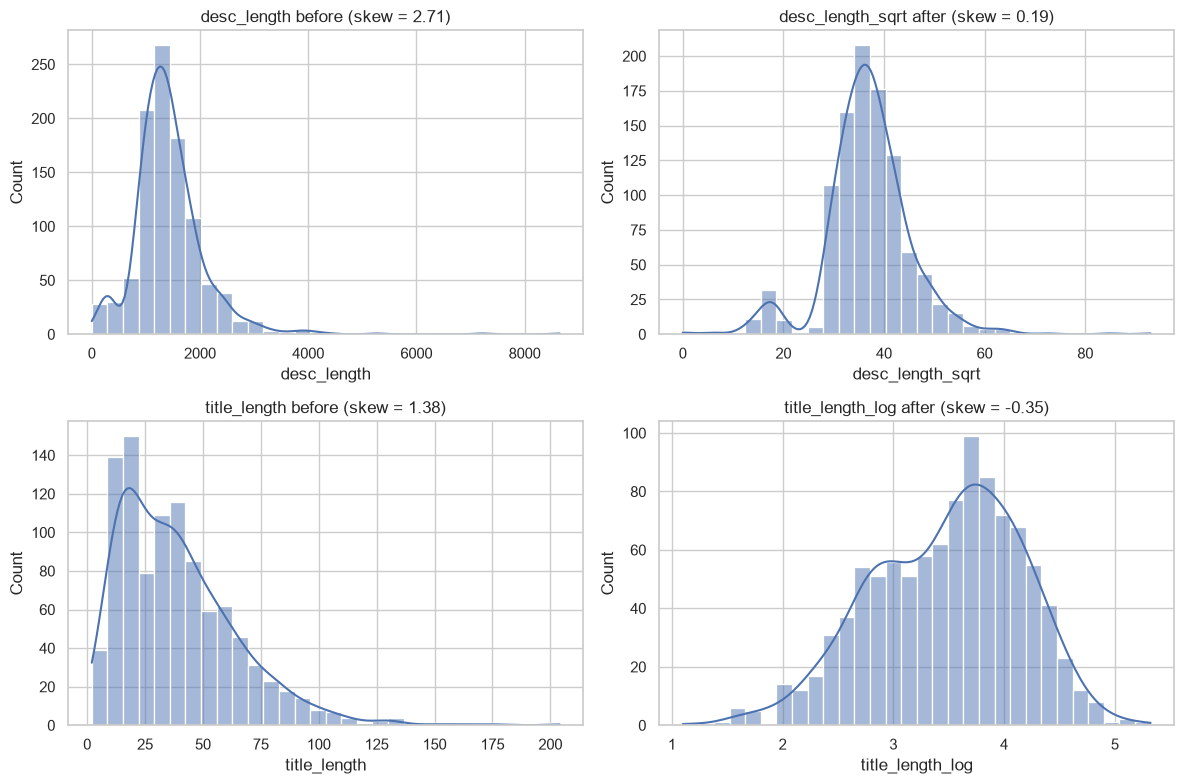

desc_length outliers: 43
desc_length_sqrt outliers: 85
title_length outliers: 20
title_length_log outliers: 2


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
pairs = [("desc_length", "desc_length_sqrt"), ("title_length", "title_length_log")]
for row, (old, new) in enumerate(pairs):
    sns.histplot(clean[old], bins=30, kde=True, ax=axes[row, 0])
    axes[row, 0].set_title(f"{old} before (skew = {clean[old].skew():.2f})")
    sns.histplot(clean[new], bins=30, kde=True, ax=axes[row, 1])
    axes[row, 1].set_title(f"{new} after (skew = {clean[new].skew():.2f})")
save_fig("skew_before_after.png")

for col in ["desc_length", "desc_length_sqrt", "title_length", "title_length_log"]:
    q1, q3 = clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((clean[col] < q1 - 1.5 * iqr) | (clean[col] > q3 + 1.5 * iqr)).sum()
    print(col, "outliers:", n)

### What this cell shows:
The histograms show title length now looks close to a bell shape. Description length is much more balanced than before. Title length outliers dropped from 20 to 2. Description length outliers went from 43 to 85. The transformations improved both distributions.

In [20]:
reg_features_num = ["stock", "desc_length_sqrt", "title_length_log", "rating_num"]
clf_features_num = ["price", "stock", "desc_length_sqrt", "title_length_log"]

assert not {"price", "price_excl_tax", "price_incl_tax", "tax"} & set(reg_features_num)
assert not {"rating", "rating_num", "rating_class"} & set(clf_features_num)
print("Regression numeric inputs:", reg_features_num)
print("Classification numeric inputs:", clf_features_num)

Regression numeric inputs: ['stock', 'desc_length_sqrt', 'title_length_log', 'rating_num']
Classification numeric inputs: ['price', 'stock', 'desc_length_sqrt', 'title_length_log']


### What this cell shows:
The models will use the transformed features. Price, stock and rating were not transformed because they were already symmetric. The leakage checks passed.

In [21]:
clean.to_csv(PROCESSED_PATH, index=False)
print("Saved", clean.shape, "to", PROCESSED_PATH)

Saved (1000, 20) to C:\Users\DELL\data\E-commerce\data\processed\books_clean.csv


### What this cell does:
The updated cleaned data was saved with the two new columns. The raw file was not changed.

In [28]:
check_cols = ["price", "stock", "desc_length", "title_length"]

def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

def z_flags(s, threshold=3):
    return ((s - s.mean()) / s.std()).abs() > threshold

flags = pd.DataFrame(index=clean.index)
rows = []
for col in check_cols:
    flags[col + "_iqr"] = iqr_flags(clean[col])
    flags[col + "_z"] = z_flags(clean[col])
    a, b = flags[col + "_iqr"], flags[col + "_z"]
    rows.append({"feature": col, "IQR": a.sum(), "Z-score": b.sum(),
                 "both": (a & b).sum(), "IQR only": (a & ~b).sum(), "Z only": (~a & b).sum()})
display(pd.DataFrame(rows))

,feature,IQR,Z-score,both,IQR only,Z only
0,price,0,0,0,0,0
1,stock,0,0,0,0,0
2,desc_length,43,12,12,31,0
3,title_length,20,11,11,9,0


### What this cell shows:
I used the IQR rule and the Z-score rule on price, stock, description length and title length. Price and stock have no outliers. Description length has 43 outliers by IQR and 12 by Z-score, and title length has 20 by IQR and 11 by Z-score. Every Z-score outlier was also found by IQR, but IQR found more. Z-score finds fewer because it assumes a bell shape and the long tails make the standard deviation larger.

In [29]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.02, random_state=SEED)
flags["isoforest"] = iso.fit_predict(clean[check_cols]) == -1
print("Isolation Forest flagged:", flags["isoforest"].sum())

any_uni = flags[[c for c in flags.columns if c.endswith("_iqr") or c.endswith("_z")]].any(axis=1)
print("Flagged by a single-feature rule:", any_uni.sum())
print("Flagged by Isolation Forest and a single-feature rule:", (any_uni & flags["isoforest"]).sum())

Isolation Forest flagged: 20
Flagged by a single-feature rule: 61
Flagged by Isolation Forest and a single-feature rule: 19


### What this cell shows:
Isolation Forest looks at all four features together. It flagged 20 books, but this number is mostly because of the setting of 2 percent, so it is not a finding by itself. 19 of these 20 were also flagged by the IQR or Z-score rules, so the methods agree strongly. In total 61 books were flagged by the single-feature rules.

In [30]:
cols = ["title", "category", "price", "stock", "desc_length", "title_length"]

print("Rows with no description:", (clean["description"] == "").sum())
print("Impossible values (zero or negative price or stock):", (clean[["price", "stock"]] <= 0).sum().sum())

print("\nShortest descriptions")
display(clean.nsmallest(8, "desc_length")[cols])
print("Longest descriptions")
display(clean.nlargest(8, "desc_length")[cols])
print("Longest titles")
display(clean.nlargest(8, "title_length")[cols])

Rows with no description: 2
Impossible values (zero or negative price or stock): 0

Shortest descriptions


,title,category,price,stock,desc_length,title_length
160,The Bridge to Consciousness: I'm Wri...,Default,32.00,15.0,0.0,96.0
995,Alice in Wonderland (Alice's Adventu...,Classics,55.53,1.0,0.0,57.0
897,Kindle Paperwhite User's Guide,Nonfiction,34.00,2.0,30.0,30.0
312,"Eat Fat, Get Thin",Health,54.07,14.0,45.0,17.0
611,Peak: Secrets from the New Science o...,Science,16.28,5.0,154.0,47.0
457,Smarter Faster Better: The Secrets o...,Nonfiction,38.89,8.0,155.0,75.0
243,The Long Haul (Diary of a Wimpy Kid #9),Humor,44.07,14.0,156.0,39.0
470,Les Fleurs du Mal,Poetry,29.04,8.0,161.0,17.0


Longest descriptions


,title,category,price,stock,desc_length,title_length
512,Team of Rivals: The Political Genius...,Add a comment,20.12,7.0,8646.0,55.0
394,The Art of Startup Fundraising,Business,21.00,11.0,7221.0,30.0
330,Buying In: The Secret Dialogue Betwe...,Nonfiction,37.80,14.0,5254.0,65.0
55,The Torch Is Passed: A Harding Famil...,Add a comment,19.09,16.0,4374.0,43.0
528,John Adams,Add a comment,57.43,7.0,4146.0,10.0
639,America's War for the Greater Middle...,History,51.22,5.0,4046.0,61.0
551,The Joy of Cooking,Add a comment,43.27,6.0,4011.0,18.0
436,If I Gave You God's Phone Number.......,Spirituality,20.91,9.0,3931.0,75.0


Longest titles


,title,category,price,stock,desc_length,title_length
541,"At The Existentialist Café: Freedom,...",Philosophy,29.93,7.0,1751.0,204.0
22,Foolproof Preserving: A Guide to Sma...,Food and Drink,30.52,19.0,1037.0,175.0
83,"Political Suicide: Missteps, Peccadi...",History,36.28,16.0,1404.0,163.0
63,The Mindfulness and Acceptance Workb...,Add a comment,23.89,16.0,2763.0,150.0
434,NaNo What Now? Finding your editing ...,Default,10.41,9.0,1496.0,133.0
389,A la Mode: 120 Recipes in 60 Pairing...,Food and Drink,38.77,12.0,1611.0,131.0
663,Orchestra of Exiles: The Story of Br...,Music,12.36,4.0,2321.0,131.0
756,The Disappearing Spoon: And Other Tr...,Science,57.35,3.0,1416.0,131.0


### What this cell shows:
This cell lists the flagged books. The longest titles belong to real books with long subtitles, for example At The Existentialist Cafe with 204 characters. Price and stock have no zero or negative values, because the minimum price is 10.00 and the minimum stock is 1. The shortest description length of 0 comes from the 2 books that have no description.

In [31]:
long_desc = clean.nlargest(3, "desc_length")
for _, r in long_desc.iterrows():
    print(r["title"], "|", int(r["desc_length"]), "characters")
    print(r["description"][:200], "...\n")

long_title = clean.nlargest(5, "title_length")
display(long_title[["title", "title_length", "category"]])

Team of Rivals: The Political Genius of Abraham Lincoln | 8646 characters
The life and times of Abraham Lincoln have been analyzed and dissected in countless books. Do we need another Lincoln biography? In Team of Rivals, esteemed historian Doris Kearns Goodwin proves that  ...

The Art of Startup Fundraising | 7221 characters
The Art of Startup Fundraising takes a fresh look at raising money for startups, with a focus on the changing face of startup finance. New regulations are making the old go-to advice less relevant, as ...

Buying In: The Secret Dialogue Between What We Buy and Who We Are | 5254 characters
“Fascinating … A compelling blend of cultural anthropology and business journalism.” — Andrea Sachs, Time Magazine “An often startling tour of new cultural terrain.” — Laura Miller, Salon “Marked by m ...



,title,title_length,category
541,"At The Existentialist Café: Freedom,...",204.0,Philosophy
22,Foolproof Preserving: A Guide to Sma...,175.0,Food and Drink
83,"Political Suicide: Missteps, Peccadi...",163.0,History
63,The Mindfulness and Acceptance Workb...,150.0,Add a comment
434,NaNo What Now? Finding your editing ...,133.0,Default


### What this cell shows:
This cell reads the longest descriptions and titles. The longest description is 8646 characters for Team of Rivals, and it is real book text. The Art of Startup Fundraising has a long real description too. Buying In is long because it includes several review quotes. The long titles are real titles with subtitles. So the flagged values are genuine and not scraping errors.

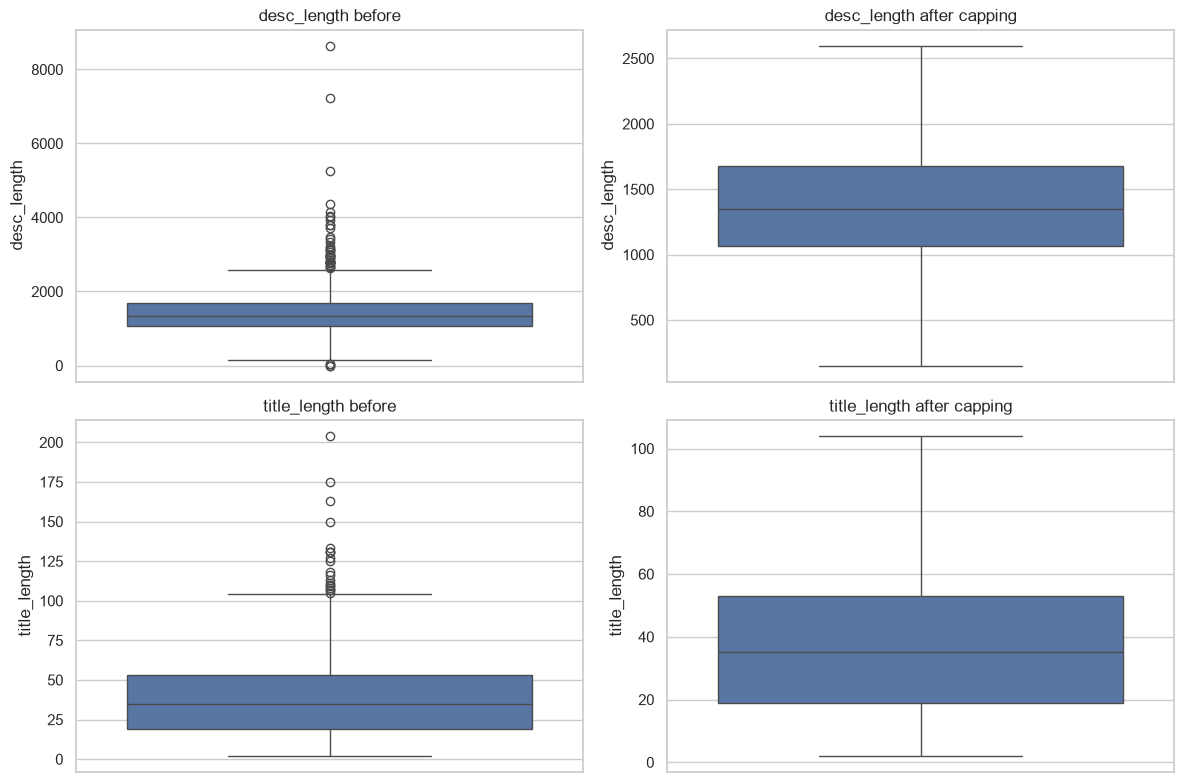

,mean_before,mean_after,std_before,std_after,skew_before,skew_after
desc_length,1431.63,1397.76,669.32,528.62,2.71,0.26
title_length,39.10,38.60,25.75,23.95,1.38,0.84


In [32]:
treated = clean.copy()
for col in ["desc_length", "title_length"]:
    q1, q3 = clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    treated[col] = clean[col].clip(lower=q1 - 1.5 * iqr, upper=q3 + 1.5 * iqr)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, col in enumerate(["desc_length", "title_length"]):
    sns.boxplot(y=clean[col], ax=axes[row, 0])
    axes[row, 0].set_title(f"{col} before")
    sns.boxplot(y=treated[col], ax=axes[row, 1])
    axes[row, 1].set_title(f"{col} after capping")
save_fig("outliers_before_after.png")

summary = pd.DataFrame({
    "mean_before": clean[["desc_length", "title_length"]].mean(),
    "mean_after": treated[["desc_length", "title_length"]].mean(),
    "std_before": clean[["desc_length", "title_length"]].std(),
    "std_after": treated[["desc_length", "title_length"]].std(),
    "skew_before": clean[["desc_length", "title_length"]].skew(),
    "skew_after": treated[["desc_length", "title_length"]].skew()})
display(summary.round(2))

### What this cell shows:
This cell caps description length and title length at the IQR limits on a copy of the data. After capping, the box plots show no outliers. For description length the standard deviation fell from 669.32 to 528.62 and the skew from 2.71 to 0.26. For title length the standard deviation fell from 25.75 to 23.95 and the skew from 1.38 to 0.84. The means changed very little.

In [33]:
print("Rows in clean (no rows removed):", len(clean))

Rows in clean (no rows removed): 1000


### What we decided:
Decision:We kept all 1000 rows and did not cap the original values. The flagged values are real books with long descriptions or long titles, so removing or capping them would change real information.The long tails were already reduced in the skewness step, using square root for description length and log for title length.The 2 zero length descriptions are missing descriptions and not true outliers.

## Step 8: Feature Selection and Feature Engineering

In [4]:
import sys, hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "src" / "config.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find src/config.py. Open this notebook inside the repo.")
    ROOT = ROOT.parent
print("Repo root:", ROOT)


sys.path.append(str(ROOT / "src"))
from config import SEED
print("SEED =", SEED)


RAW_PATH = ROOT / "data" / "raw" / "books_raw.csv"
CLEAN_PATH = ROOT / "data" / "processed" / "books_clean.csv"
clean = pd.read_csv(CLEAN_PATH)
print("Shape:", clean.shape)
print("Columns:", list(clean.columns))


TARGET_REG = "price"

Repo root: d:\Sufiyan's Project\E-commerce
SEED = 3020
Shape: (1000, 20)
Columns: ['title', 'product_url', 'category', 'price_excl_tax', 'price_incl_tax', 'tax', 'rating', 'availability', 'num_reviews', 'upc', 'description', 'collected_at', 'price', 'stock', 'rating_num', 'desc_length', 'title_length', 'rating_class', 'title_length_log', 'desc_length_sqrt']


### What this cell does

This cell finds the project folder and loads the SEED from the config file. The SEED is 3020. It then loads the cleaned data from the CSV file.

### What the output shows

The output shows 1000 rows and 20 columns, so the data loaded correctly.

In [5]:
import hashlib

# Targets and feature lists
TARGET_REG = "price"
TARGET_CLF = "rating_class"
NUM_REG = ["stock", "desc_length_sqrt", "title_length_log", "rating_num"]
CAT_REG = ["category"]
NUM_CLF = ["price", "stock", "desc_length_sqrt", "title_length_log"]
CAT_CLF = ["category"]
FEATURES_REG = NUM_REG + CAT_REG
FEATURES_CLF = NUM_CLF + CAT_CLF

# Safety checks on the columns
needed = set(FEATURES_REG + FEATURES_CLF + [TARGET_REG, TARGET_CLF])
missing_cols = needed - set(clean.columns)
assert not missing_cols, f"Missing columns: {missing_cols}"
assert TARGET_REG not in FEATURES_REG
assert TARGET_CLF not in FEATURES_CLF
assert not {"rating", "rating_num", "rating_class"} & set(FEATURES_CLF), "Rating leaked into classification inputs"
assert not {"price_excl_tax", "price_incl_tax", "tax"} & set(FEATURES_REG), "Price fields leaked into regression inputs"
print("Feature checks passed.")
print("Missing values in model columns:", int(clean[list(needed)].isna().sum().sum()))
print("Rating class counts:\n", clean[TARGET_CLF].value_counts().reindex(["Low", "Medium", "High"]))

# Check the raw file fingerprint (read only, the file is not changed)
EXPECTED_SHA = "f6129f4d7f32af7fc7dff8eef0fdf57c6aca2051987da258d5dab4fa2b0db802"

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

actual_sha = sha256_of(RAW_PATH)
print("SHA-256 of raw file:", actual_sha)
print("Matches fingerprint:", actual_sha == EXPECTED_SHA)

Feature checks passed.
Missing values in model columns: 0
Rating class counts:
 rating_class
Low       422
Medium    203
High      375
Name: count, dtype: int64
SHA-256 of raw file: f6129f4d7f32af7fc7dff8eef0fdf57c6aca2051987da258d5dab4fa2b0db802
Matches fingerprint: True


### What this cell does

This cell sets the target and input columns for both tasks. The regression target is price and the classification target is rating_class. It checks that no rating column is used as a classification input and that no extra price or tax column is used as a regression input. It also checks the raw file fingerprint.

### What the output shows

All checks passed and there are no missing values in the model columns. The classes are Low 422, Medium 203 and High 375. The fingerprint matches, so the raw data has not changed.

In [6]:
clean["title_words"] = clean["title"].str.split().str.len().astype(float)
clean["desc_words"] = clean["description"].fillna("").str.split().str.len().astype(float)
clean["title_has_colon"] = clean["title"].str.contains(":", regex=False).astype(int)

display(clean[["title", "title_words", "desc_words", "title_has_colon"]].head())
print(clean[["title_words", "desc_words", "title_has_colon"]].describe().round(2))

,title,title_words,desc_words,title_has_colon
0,A Light in the Attic,5.0,164.0,0
1,Tipping the Velvet,3.0,165.0,0
2,Soumission,1.0,163.0,0
3,Sharp Objects,2.0,274.0,0
4,Sapiens: A Brief History of Humankind,6.0,304.0,1


       title_words  desc_words  title_has_colon
count      1000.00     1000.00          1000.00
mean          6.74      236.38             0.31
std           4.20      107.56             0.46
min           1.00        0.00             0.00
25%           3.00      177.00             0.00
50%           6.00      222.50             0.00
75%           9.00      279.00             1.00
max          27.00     1390.00             1.00


### What this cell does

This cell makes three new columns from the title and description of each book. They are the number of words in the title, the number of words in the description, and whether the title has a colon. These columns are only in memory and the saved CSV file is not changed.

### What the output shows

The first five rows show the new columns. For example, A Light in the Attic has 5 title words and 164 description words. Sapiens: A Brief History of Humankind has 6 title words and a colon, so title_has_colon is 1.

In [7]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    clean.index, test_size=0.2, random_state=SEED, stratify=clean[TARGET_CLF]
)
train = clean.loc[train_idx].reset_index(drop=True)
test = clean.loc[test_idx].reset_index(drop=True)

print("Train size:", len(train), "| Test size:", len(test))
print("Train class share (%):\n", (train[TARGET_CLF].value_counts(normalize=True) * 100).round(1))
print("Test class share (%):\n", (test[TARGET_CLF].value_counts(normalize=True) * 100).round(1))

Train size: 800 | Test size: 200
Train class share (%):
 rating_class
Low       42.2
High      37.5
Medium    20.2
Name: proportion, dtype: float64
Test class share (%):
 rating_class
Low       42.0
High      37.5
Medium    20.5
Name: proportion, dtype: float64


### What this cell does

This cell splits the data into 80 percent training and 20 percent testing. The split uses the SEED and keeps the share of Low, Medium and High the same in both parts. The test set is not used until the final evaluation.

### What the output shows

The training set has 800 books and the test set has 200 books. The class shares are almost the same in both sets. Low is about 42 percent, Medium about 20 percent and High about 37.5 percent.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

CATEGORICAL = ["category"]
CAND_REG = ["stock", "desc_length_sqrt", "title_length_log", "rating_num", "category",
            "title_words", "desc_words", "title_has_colon"]
CAND_CLF = ["price", "stock", "desc_length_sqrt", "title_length_log", "category",
            "title_words", "desc_words", "title_has_colon"]


assert not {"price_excl_tax", "price_incl_tax", "tax", "price"} & set(CAND_REG)
assert not {"rating", "rating_num", "rating_class"} & set(CAND_CLF)

def build_pipeline(columns, model):
    num = [c for c in columns if c not in CATEGORICAL]
    cat = [c for c in columns if c in CATEGORICAL]
    parts = []
    if num:
        parts.append(("num", StandardScaler(), num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), cat))
    return Pipeline([("prep", ColumnTransformer(parts)), ("model", model)])

reg_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_score(columns, task):
    if task == "reg":
        model = build_pipeline(columns, LinearRegression())
        return cross_val_score(model, train[columns], train[TARGET_REG], cv=reg_cv, scoring="r2").mean()
    model = build_pipeline(columns, LogisticRegression(max_iter=1000, random_state=SEED))
    return cross_val_score(model, train[columns], train[TARGET_CLF], cv=clf_cv, scoring="f1_macro").mean()

base_reg = cross_val_score(DummyRegressor(), train[["stock"]], train[TARGET_REG], cv=reg_cv, scoring="r2").mean()
base_clf = cross_val_score(DummyClassifier(strategy="most_frequent"), train[["stock"]], train[TARGET_CLF],
                           cv=clf_cv, scoring="f1_macro").mean()
print("Baseline regression R2 (always predict the mean):", round(base_reg, 4))
print("Baseline classification macro F1 (always predict the biggest class):", round(base_clf, 4))

Baseline regression R2 (always predict the mean): -0.0121
Baseline classification macro F1 (always predict the biggest class): 0.198


### What this cell does

This cell prepares the tools for feature selection. It scales the number columns and one-hot encodes the category column inside a pipeline, so only the training folds are used to fit them. It also checks that no price or rating column that reveals the target is used. Finally it calculates baseline scores for a model that ignores all the features.

### What the output shows

The baseline R2 for regression is -0.0121. The baseline macro F1 for classification is 0.198. Any real model should beat these numbers.

In [9]:
TOL = 0.001  

def forward_selection(candidates, task):
    chosen, best, log = [], None, []
    remaining = list(candidates)
    while remaining:
        scores = {f: cv_score(chosen + [f], task) for f in remaining}
        f_best = max(scores, key=scores.get)
        if best is not None and scores[f_best] - best <= TOL:
            break
        chosen.append(f_best)
        remaining.remove(f_best)
        best = scores[f_best]
        log.append(("added " + f_best, round(float(best), 4)))
    return chosen, log

def backward_elimination(candidates, task):
    chosen = list(candidates)
    current = cv_score(chosen, task)
    log = [("start with all features", round(float(current), 4))]
    while len(chosen) > 1:
        scores = {f: cv_score([c for c in chosen if c != f], task) for f in chosen}
        f_drop = max(scores, key=scores.get)
        if scores[f_drop] < current - TOL:
            break
        chosen.remove(f_drop)
        current = scores[f_drop]
        log.append(("removed " + f_drop, round(float(current), 4)))
    return chosen, log

### What this cell does

This cell defines forward selection and backward elimination. Forward selection starts with nothing and adds the feature that improves the cross-validation score most. Backward elimination starts with all features and removes the one whose removal hurts the score least. Both stop when the change is smaller than 0.001. This cell only defines functions, so it has no output.

In [10]:
fw_reg, fw_reg_log = forward_selection(CAND_REG, "reg")
bw_reg, bw_reg_log = backward_elimination(CAND_REG, "reg")

print("REGRESSION, forward selection (CV R2 after each step)")
for step, score in fw_reg_log:
    print("  ", step, "->", score)
print("Selected:", fw_reg)

print("\nREGRESSION, backward elimination (CV R2 after each step)")
for step, score in bw_reg_log:
    print("  ", step, "->", score)
print("Selected:", bw_reg)

REGRESSION, forward selection (CV R2 after each step)
   added desc_length_sqrt -> -0.0116
   added desc_words -> -0.0087
Selected: ['desc_length_sqrt', 'desc_words']

REGRESSION, backward elimination (CV R2 after each step)
   start with all features -> -0.057
   removed category -> -0.0159
   removed title_words -> -0.0114
   removed stock -> -0.0107
   removed title_length_log -> -0.0103
   removed title_has_colon -> -0.0091
   removed rating_num -> -0.0087
Selected: ['desc_length_sqrt', 'desc_words']


### What this cell does

This cell runs forward selection and backward elimination for the price prediction task and prints each step with its score.

### What the output shows

Both methods select the same two features, desc_length_sqrt and desc_words. The best score is -0.0087, which is only slightly better than the baseline of -0.0121. All scores are below zero, so these features cannot predict price. Backward elimination started with all features at -0.057, and the score improved as features were removed.

In [11]:
fw_clf, fw_clf_log = forward_selection(CAND_CLF, "clf")
bw_clf, bw_clf_log = backward_elimination(CAND_CLF, "clf")

print("CLASSIFICATION, forward selection (CV macro F1 after each step)")
for step, score in fw_clf_log:
    print("  ", step, "->", score)
print("Selected:", fw_clf)

print("\nCLASSIFICATION, backward elimination (CV macro F1 after each step)")
for step, score in bw_clf_log:
    print("  ", step, "->", score)
print("Selected:", bw_clf)

CLASSIFICATION, forward selection (CV macro F1 after each step)
   added category -> 0.3028
   added price -> 0.3109
Selected: ['category', 'price']

CLASSIFICATION, backward elimination (CV macro F1 after each step)
   start with all features -> 0.306
   removed title_length_log -> 0.3149
   removed title_words -> 0.3146
   removed title_has_colon -> 0.3163
Selected: ['price', 'stock', 'desc_length_sqrt', 'category', 'desc_words']


### What this cell does

This cell runs forward selection and backward elimination for the rating class task and prints each step with its score.

### What the output shows

Forward selection chose category and price with a macro F1 of 0.3109. Backward elimination kept price, stock, desc_length_sqrt, category and desc_words with a macro F1 of 0.3163. Both are above the baseline of 0.198, but the gain is small. Both methods keep category and price.

In [12]:
rows = [
    {"task": "Regression", "method": "Baseline", "features": "none", "cv_score": round(float(base_reg), 4)},
    {"task": "Regression", "method": "All candidates", "features": ", ".join(CAND_REG), "cv_score": round(float(cv_score(CAND_REG, "reg")), 4)},
    {"task": "Regression", "method": "Forward", "features": ", ".join(fw_reg), "cv_score": round(float(cv_score(fw_reg, "reg")), 4)},
    {"task": "Regression", "method": "Backward", "features": ", ".join(bw_reg), "cv_score": round(float(cv_score(bw_reg, "reg")), 4)},
    {"task": "Classification", "method": "Baseline", "features": "none", "cv_score": round(float(base_clf), 4)},
    {"task": "Classification", "method": "All candidates", "features": ", ".join(CAND_CLF), "cv_score": round(float(cv_score(CAND_CLF, "clf")), 4)},
    {"task": "Classification", "method": "Forward", "features": ", ".join(fw_clf), "cv_score": round(float(cv_score(fw_clf, "clf")), 4)},
    {"task": "Classification", "method": "Backward", "features": ", ".join(bw_clf), "cv_score": round(float(cv_score(bw_clf, "clf")), 4)},
]
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(rows))
print("Common to forward and backward (regression):", sorted(set(fw_reg) & set(bw_reg)))
print("Common to forward and backward (classification):", sorted(set(fw_clf) & set(bw_clf)))

,task,method,features,cv_score
0,Regression,Baseline,none,-0.0121
1,Regression,All candidates,"stock, desc_length_sqrt, title_length_log, rating_num, category, title_words, desc_words, title_has_colon",-0.0570
2,Regression,Forward,"desc_length_sqrt, desc_words",-0.0087
3,Regression,Backward,"desc_length_sqrt, desc_words",-0.0087
4,Classification,Baseline,none,0.1980
5,Classification,All candidates,"price, stock, desc_length_sqrt, title_length_log, category, title_words, desc_words, title_has_colon",0.3060
6,Classification,Forward,"category, price",0.3109
7,Classification,Backward,"price, stock, desc_length_sqrt, category, desc_words",0.3163


Common to forward and backward (regression): ['desc_length_sqrt', 'desc_words']
Common to forward and backward (classification): ['category', 'price']


### What this cell does

This cell puts the baseline, all features, forward selection and backward elimination into one table for each task so that they can be compared.

### What the output shows

For regression, the selected features score -0.0087, better than all features at -0.0570 and slightly better than the baseline at -0.0121. For classification, forward selection scores 0.3109 and backward elimination scores 0.3163, compared with 0.3060 for all features and 0.1980 for the baseline. The two methods give the same set for regression. For classification they share category and price.

### Feature selection summary

For regression the target is price. The price excluding tax, price including tax and tax columns are not used because they repeat the target. For classification the target is rating_class. The rating and rating number are not used because the classes are made from them. The columns tax and num_reviews are constant, so they are not used.

For regression, forward selection and backward elimination gave the same two features. Both are about the length of the description, so they carry almost the same information. The scores are all close to zero, so price cannot be predicted well from these features. This agrees with the EDA, where price had almost no correlation with any feature.

For classification, forward selection gave a smaller set than backward elimination. Both kept category and price. The scores are only a little above the baseline, so the features give weak information about the rating class.

The selected sets will be used in the modelling steps. Weak model results will be reported as they are.

 ## Step 9: train-test split

In [13]:
print("Rows in train:", len(train), "| Rows in test:", len(test))
print("Train plus test equals all rows:", len(train) + len(test) == len(clean))
print("Same book in both sets:", len(set(train["upc"]) & set(test["upc"])))

Rows in train: 800 | Rows in test: 200
Train plus test equals all rows: True
Same book in both sets: 0


### What this cell does:
This cell checks the train and test split made earlier. The split is 80 percent train and 20 percent test, and it is stratified on rating_class so that Low, Medium and High have almost the same share in both sets. We used a random split with the SEED because the books have no time order and each row is a different book. The output shows 800 training rows and 200 test rows, which add up to all 1000 rows. No book appears in both sets.

In [14]:
FINAL_REG = list(fw_reg)
FINAL_CLF = list(bw_clf)

y_train_reg, y_test_reg = train[TARGET_REG], test[TARGET_REG]
y_train_clf, y_test_clf = train[TARGET_CLF], test[TARGET_CLF]

TRAIN_SIZE, TEST_SIZE = len(train), len(test)

print("Regression features:", FINAL_REG)
print("Classification features:", FINAL_CLF)
print("Train size:", TRAIN_SIZE, "| Test size:", TEST_SIZE)

Regression features: ['desc_length_sqrt', 'desc_words']
Classification features: ['price', 'stock', 'desc_length_sqrt', 'category', 'desc_words']
Train size: 800 | Test size: 200


### What this cell does:
This cell saves the final features and targets for both tasks. Regression uses desc_length_sqrt and desc_words, which were chosen by forward selection and backward elimination. Classification uses price, stock, desc_length_sqrt, category and desc_words, which were chosen by backward elimination because it had the best cross-validation score. It also saves the train and test sizes for the training log. The output shows 800 train rows and 200 test rows.

In [15]:
def make_preprocessor(columns):
    num = [c for c in columns if c not in CATEGORICAL]
    cat = [c for c in columns if c in CATEGORICAL]
    parts = []
    if num:
        parts.append(("num", StandardScaler(), num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), cat))
    return ColumnTransformer(parts)

def to_array(x):
    return x.toarray() if hasattr(x, "toarray") else x

prep_reg = make_preprocessor(FINAL_REG)
X_train_reg = to_array(prep_reg.fit_transform(train[FINAL_REG]))
X_test_reg = to_array(prep_reg.transform(test[FINAL_REG]))

prep_clf = make_preprocessor(FINAL_CLF)
X_train_clf = to_array(prep_clf.fit_transform(train[FINAL_CLF]))
X_test_clf = to_array(prep_clf.transform(test[FINAL_CLF]))

n_reg = len([c for c in FINAL_REG if c not in CATEGORICAL])
n_clf = len([c for c in FINAL_CLF if c not in CATEGORICAL])

print("Regression shapes: train", X_train_reg.shape, "| test", X_test_reg.shape)
print("Classification shapes: train", X_train_clf.shape, "| test", X_test_clf.shape)
print("Regression scaled means: train", X_train_reg[:, :n_reg].mean(axis=0).round(3),
      "| test", X_test_reg[:, :n_reg].mean(axis=0).round(3))
print("Classification scaled means: train", X_train_clf[:, :n_clf].mean(axis=0).round(3),
      "| test", X_test_clf[:, :n_clf].mean(axis=0).round(3))

Regression shapes: train (800, 2) | test (200, 2)
Classification shapes: train (800, 25) | test (200, 25)
Regression scaled means: train [ 0. -0.] | test [0.037 0.029]
Classification scaled means: train [-0.  0.  0. -0.] | test [0.029 0.012 0.037 0.029]


### What this cell does:
This cell scales the number columns and one-hot encodes category. The scaler and encoder learn only from the training data, and then the same fitted steps are applied to the test data without fitting again. The square root and log changes from Step 6 are fixed formulas that learn nothing from the data, so they do not leak test information. The output shows 2 columns for regression and 25 columns for classification. The training means are 0, and the test means are close to 0 but not exactly 0, which shows the test data was not used for fitting. The test set is kept aside until the final evaluation.

## Step 10: Regression Task

In [16]:
constant_cols = [c for c in clean.columns if clean[c].nunique() == 1]
print("Constant columns, not used:", constant_cols)
print("Price or tax columns in the inputs:", bool({"price_excl_tax", "price_incl_tax", "tax"} & set(FINAL_REG)))
print("Target in the inputs:", TARGET_REG in FINAL_REG)

Constant columns, not used: ['tax', 'num_reviews']
Price or tax columns in the inputs: False
Target in the inputs: False


### What this cell does:
This cell checks the inputs for regression. The columns tax and num_reviews are constant, so they are not used. The price excluding tax, price including tax and tax columns are not in the inputs, and the target price is not in the inputs either. This avoids leaking the target.

In [17]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_models = {
    "Baseline (mean)": DummyRegressor(),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}

def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

reg_fitted = {}
rows = []
for name, model in reg_models.items():
    pipe = Pipeline([("prep", make_preprocessor(FINAL_REG)), ("model", model)])
    pipe.fit(train[FINAL_REG], y_train_reg)
    reg_fitted[name] = pipe
    for part, X, y in [("train", train[FINAL_REG], y_train_reg), ("test", test[FINAL_REG], y_test_reg)]:
        rows.append({"model": name, "set": part, **reg_metrics(y, pipe.predict(X))})

reg_results = pd.DataFrame(rows)
print("Models trained:", list(reg_fitted))

Models trained: ['Baseline (mean)', 'Linear Regression', 'Random Forest', 'Gradient Boosting']


### What this cell does:
This cell trains three regression models, Linear Regression, Random Forest and Gradient Boosting. It also trains a baseline that always predicts the mean price, to check whether the models learn anything. The scaler is inside a pipeline and is fitted on the training data only. The cell calculates MAE, MSE, RMSE and R2 on both the train and test sets. The output shows that all four models were trained.

In [18]:
test_table = reg_results[reg_results["set"] == "test"].drop(columns="set").set_index("model").round(4)
train_table = reg_results[reg_results["set"] == "train"].drop(columns="set").set_index("model").round(4)

print("Test results")
display(test_table)
print("Train results")
display(train_table)

Test results


,MAE,MSE,RMSE,R2
model,,,,
Baseline (mean),12.5191,209.9089,14.4882,-0.0009
Linear Regression,12.6304,214.4529,14.6442,-0.0225
Random Forest,13.6372,250.4407,15.8253,-0.1941
Gradient Boosting,13.3406,239.0375,15.4608,-0.1398


Train results


,MAE,MSE,RMSE,R2
model,,,,
Baseline (mean),12.5313,208.1545,14.4276,0.0000
Linear Regression,12.4632,206.8069,14.3808,0.0065
Random Forest,9.8287,134.1860,11.5839,0.3554
Gradient Boosting,10.3631,147.5952,12.1489,0.2909


### What this cell does:
This cell trains three regression models, Linear Regression, Random Forest and Gradient Boosting. It also trains a baseline that always predicts the mean price, to check whether the models learn anything. The scaler is inside a pipeline and is fitted on the training data only. The cell calculates MAE, MSE, RMSE and R2 on both the train and test sets. The output shows that all four models were trained.

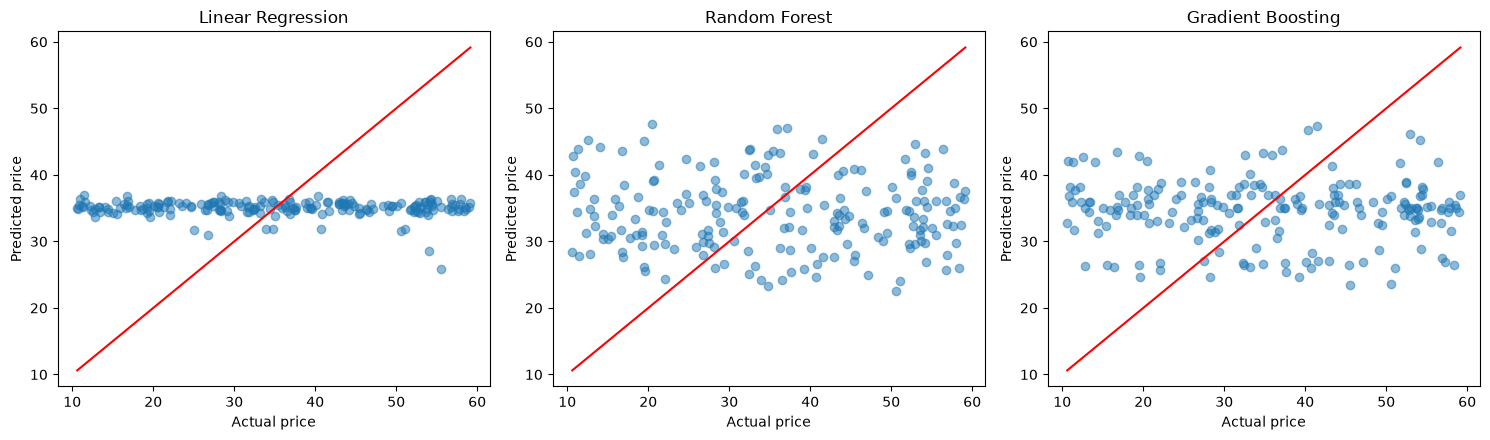

In [19]:
import matplotlib.pyplot as plt

FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, ["Linear Regression", "Random Forest", "Gradient Boosting"]):
    pred = reg_fitted[name].predict(test[FINAL_REG])
    ax.scatter(y_test_reg, pred, alpha=0.5)
    lim = [y_test_reg.min(), y_test_reg.max()]
    ax.plot(lim, lim, color="red")
    ax.set_title(name)
    ax.set_xlabel("Actual price")
    ax.set_ylabel("Predicted price")
plt.tight_layout()
plt.savefig(FIG_DIR / "regression_actual_vs_predicted.png", dpi=150)
plt.show()

### What this cell does:
This cell plots the actual price against the predicted price on the test set for each model. A good model would have points close to the red line. The Linear Regression points form a flat line near the average price, so it predicts almost the same value for every book. The Random Forest and Gradient Boosting points are spread around with no pattern. The plots show that none of the models can predict price well.

## Step 11: Classification Task

In [27]:
order = ["Low", "Medium", "High"]

print(clean[["rating_num", "rating_class"]].drop_duplicates().sort_values("rating_num").to_string(index=False))
print()
print(clean[TARGET_CLF].value_counts().reindex(order))
print((clean[TARGET_CLF].value_counts(normalize=True).reindex(order) * 100).round(1))
print()
print("Rating columns in the inputs:", bool({"rating", "rating_num", "rating_class"} & set(FINAL_CLF)))

 rating_num rating_class
          1          Low
          2          Low
          3       Medium
          4         High
          5         High

rating_class
Low       422
Medium    203
High      375
Name: count, dtype: int64
rating_class
Low       42.2
Medium    20.3
High      37.5
Name: proportion, dtype: float64

Rating columns in the inputs: False


### What this cell does:
This cell shows how the rating classes are made and how many books are in each class. Low is 1 and 2 stars, Medium is 3 stars and High is 4 and 5 stars. There are 422 Low books (42.2 percent), 203 Medium books (20.3 percent) and 375 High books (37.5 percent). Medium is the smallest class, so the data is imbalanced. The star rating columns are not used as inputs.

In [28]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

clf_models = {
    "Baseline (biggest class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

def class_proba(pipe, X):
    p = pipe.predict_proba(X)
    idx = [list(pipe.classes_).index(c) for c in order]
    return p[:, idx]

def clf_metrics(pipe, X, y):
    pred = pipe.predict(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, average="macro", zero_division=0),
        "Recall": recall_score(y, pred, average="macro", zero_division=0),
        "F1": f1_score(y, pred, average="macro", zero_division=0),
        "AUC": roc_auc_score(y, pipe.predict_proba(X), multi_class="ovr", average="macro"),
    }

clf_fitted = {}
rows = []
for name, model in clf_models.items():
    pipe = Pipeline([("prep", make_preprocessor(FINAL_CLF)), ("model", model)])
    pipe.fit(train[FINAL_CLF], y_train_clf)
    clf_fitted[name] = pipe
    for part, X, y in [("train", train[FINAL_CLF], y_train_clf), ("test", test[FINAL_CLF], y_test_clf)]:
        rows.append({"model": name, "set": part, **clf_metrics(pipe, X, y)})

clf_results = pd.DataFrame(rows)
print("Models trained:", list(clf_fitted))

Models trained: ['Baseline (biggest class)', 'Logistic Regression', 'Random Forest', 'Gradient Boosting']


### What this cell does:
This cell trains three classification models, Logistic Regression, Random Forest and Gradient Boosting. It also trains a baseline that always predicts the biggest class. The scaler and encoder are inside a pipeline and are fitted on the training data only. The cell calculates accuracy, precision, recall, F1 and AUC on the train and test sets. Precision, recall, F1 and AUC are macro averages, so each class counts equally. The output shows that all four models were trained.

In [33]:
clf_test = clf_results[clf_results["set"] == "test"].drop(columns="set").set_index("model").round(4)
clf_train = clf_results[clf_results["set"] == "train"].drop(columns="set").set_index("model").round(4)

print("Test results")
display(clf_test)
print("Train results")
display(clf_train)

Test results


,Accuracy,Precision,Recall,F1,AUC
model,,,,,
Baseline (biggest class),0.42,0.1400,0.3333,0.1972,0.5000
Logistic Regression,0.41,0.2737,0.3387,0.2979,0.4812
Random Forest,0.38,0.2512,0.3144,0.2770,0.4795
Gradient Boosting,0.37,0.2896,0.3140,0.2919,0.4830


Train results


,Accuracy,Precision,Recall,F1,AUC
model,,,,,
Baseline (biggest class),0.4225,0.1408,0.3333,0.1980,0.5000
Logistic Regression,0.4788,0.3205,0.3931,0.3441,0.6082
Random Forest,0.6950,0.7991,0.5919,0.5597,0.9256
Gradient Boosting,0.7775,0.8332,0.7258,0.7478,0.9431


### What this cell does:
This cell shows the results on the test and train sets. On the test set the baseline has an accuracy of 0.42, which is higher than Logistic Regression (0.41), Random Forest (0.38) and Gradient Boosting (0.37). The macro F1 of the models is between 0.2770 and 0.2979, but the baseline is only 0.1972 because it never predicts Medium or High. The AUC of all three models is about 0.48, which is no better than guessing. Random Forest and Gradient Boosting have train AUC of 0.9256 and 0.9431, so they overfit badly. The features do not predict the rating class.

In [30]:
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    print(name)
    print(classification_report(y_test_clf, clf_fitted[name].predict(test[FINAL_CLF]), labels=order, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

         Low       0.42      0.64      0.50        84
      Medium       0.00      0.00      0.00        41
        High       0.41      0.37      0.39        75

    accuracy                           0.41       200
   macro avg       0.27      0.34      0.30       200
weighted avg       0.33      0.41      0.36       200

Random Forest
              precision    recall  f1-score   support

         Low       0.40      0.58      0.47        84
      Medium       0.00      0.00      0.00        41
        High       0.36      0.36      0.36        75

    accuracy                           0.38       200
   macro avg       0.25      0.31      0.28       200
weighted avg       0.30      0.38      0.33       200

Gradient Boosting
              precision    recall  f1-score   support

         Low       0.38      0.46      0.42        84
      Medium       0.10      0.02      0.04        41
        High       0.39

### What this cell does:
This cell shows precision, recall and F1 for each class and each model on the test set. All three models fail on the Medium class. Logistic Regression and Random Forest have precision, recall and F1 of 0.00 for Medium, and Gradient Boosting has a recall of only 0.02. This is the effect of class imbalance, because Medium has the fewest books. The models do a little better on Low and High, but their F1 scores are only between 0.36 and 0.50. Logistic Regression has the best Low F1 (0.50) and Random Forest is lower (0.47). The macro F1 is low for all models (0.30, 0.28 and 0.29) because Medium pulls the average down.

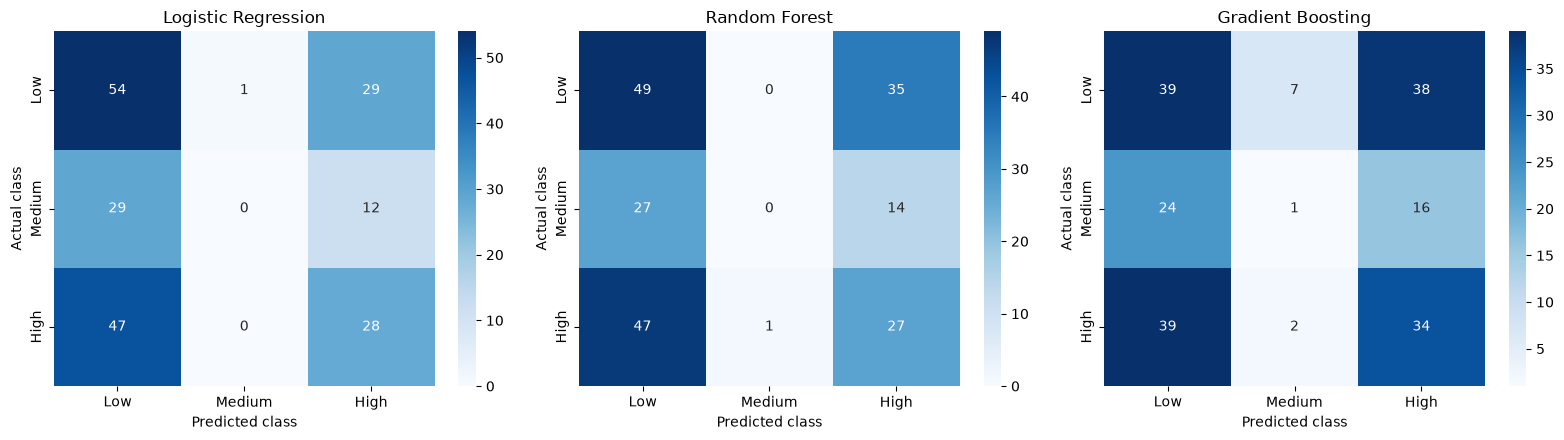

In [31]:
import seaborn as sns

model_names = ["Logistic Regression", "Random Forest", "Gradient Boosting"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, model_names):
    cm = confusion_matrix(y_test_clf, clf_fitted[name].predict(test[FINAL_CLF]), labels=order)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
plt.tight_layout()
plt.savefig(FIG_DIR / "classification_confusion_matrices.png", dpi=150)
plt.show()

### What this cell does:
This cell shows a confusion matrix for each model on the test set. The rows are the actual classes and the columns are the predicted classes. The models mostly predict Low or High. Logistic Regression and Random Forest predict Medium for only one book each, and Gradient Boosting for ten books. Medium books are mostly predicted as Low or High. Many High books are also predicted as Low, so the models cannot separate the classes well.

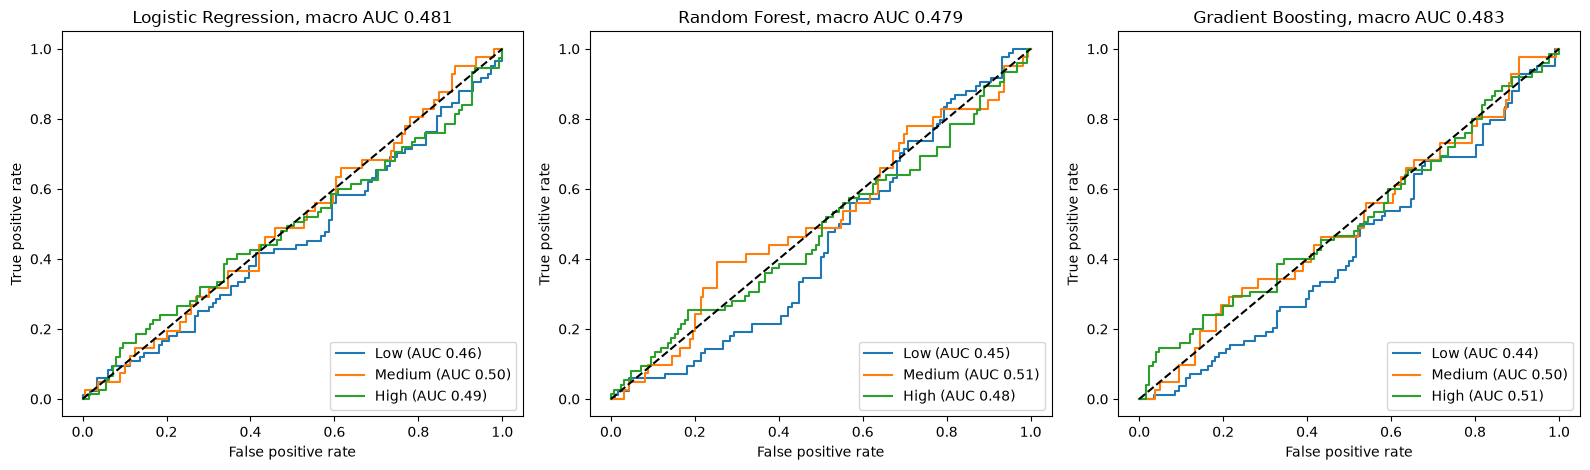

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, name in zip(axes, model_names):
    proba = class_proba(clf_fitted[name], test[FINAL_CLF])
    for i, cls in enumerate(order):
        y_bin = (y_test_clf == cls).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, proba[:, i])
        ax.plot(fpr, tpr, label=f"{cls} (AUC {roc_auc_score(y_bin, proba[:, i]):.2f})")
    ax.plot([0, 1], [0, 1], "k--")
    macro_auc = roc_auc_score(y_test_clf, clf_fitted[name].predict_proba(test[FINAL_CLF]), multi_class="ovr", average="macro")
    ax.set_title(f"{name}, macro AUC {macro_auc:.3f}")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "classification_roc_curves.png", dpi=150)
plt.show()

### What this cell does:
This cell plots one-vs-rest ROC curves for each model, with one curve for each class. A curve far above the dotted diagonal line means a good model. Here the curves stay close to the diagonal. The macro AUC is 0.481 for Logistic Regression, 0.479 for Random Forest and 0.483 for Gradient Boosting. This means the models are not better than random guessing.